# Práctica 2: Reducción de dimensiones con PCA, Sammon y Autocodificadores

**Instituto Politécnico Nacional, Escuela Superior de Cómputo (ESCOM)**
**Asignatura:** Analítica y Visualización de Datos
**Profesor:** Ituriel Enrique Flores Estrada
**Equipo:** Melanie, Magaly, Ricardo y Santiago

**Conjunto de datos:** Breast Cancer Wisconsin (Diagnostic).

**Objetivo:** proyectar los datos a 3 dimensiones con PCA, Sammon, Sammon sobre PCA y un autocodificador no lineal, comparar los métodos y presentar los resultados en un tablero.

> Este es el **único notebook** de la entrega. Se edita por turnos y cada quien trabaja solo en su sección (ver `README.md`). Cada sección usa únicamente lo definido antes de ella, así que debe poder ejecutarse con *Restart & Run All*.

## Sección 0. Preparación común
**Responsable:** Melanie

**Propósito:** dejar en un solo lugar las librerías, la semilla, los colores y las funciones que usa todo el equipo, para que los resultados de los cuatro métodos se midan igual y se puedan comparar.

**Insumo:** dataset 17 del repositorio UCI, descargado por código. **Resultado:** `X`, `X_std`, `y` y las funciones compartidas.

In [1]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Descripción: Importación de librerías y definición de semilla, colores y rutas.
# Insumo:      ninguno.
# Resultado:   constantes comunes a todas las secciones.
# ===========================================================
# --- LIBRERÍAS ---
# "import x" carga una librería completa; se usa como x.funcion().
# "import x as y" le pone un nombre corto; por ejemplo, np.mean() en lugar de numpy.mean().
# "from x import y" trae solo una parte; se usa directamente como y().

import platform                   # Da datos del sistema: Windows, procesador, versión de Python
import random                     # Genera números aleatorios con Python; aquí solo se le fija la semilla
import tempfile                   # Crea carpetas temporales que se borran solas; se usa en las pruebas
from pathlib import Path          # Representa rutas de archivos; une carpetas con "/" en cualquier sistema
from time import perf_counter     # Cronómetro de alta precisión; lo usarán las secciones que miden tiempos

import matplotlib.pyplot as plt   # Dibuja las figuras
import numpy as np                # Hace cálculos con arreglos (listas de números muy rápidas)
import pandas as pd               # Maneja tablas; una tabla de pandas se llama DataFrame
import psutil                     # Consulta los recursos de la computadora; aquí, la RAM y los núcleos
from IPython.display import display                     # Muestra una tabla con formato en el notebook
from scipy.spatial.distance import pdist                # Calcula la distancia entre todos los pares de puntos
from sklearn.decomposition import PCA                   # Análisis de Componentes Principales
# StratifiedKFold divide los datos en partes; cross_val_score entrena y evalúa con esas partes
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier      # Clasificador k-NN (k vecinos más cercanos)
from sklearn.preprocessing import StandardScaler        # Estandariza: deja cada variable con media 0 y desviación 1
from ucimlrepo import fetch_ucirepo                     # Descarga datasets del repositorio UCI

# --- SEMILLA ---
# La computadora genera números "aleatorios" a partir de un valor inicial llamado semilla.
# Con la misma semilla salen los mismos números, así que los resultados se pueden repetir.
SEED = 42             # El valor 42 es arbitrario; lo importante es que todo el equipo use el mismo
random.seed(SEED)     # Fija la semilla del generador de Python
np.random.seed(SEED)  # Fija la semilla del generador de NumPy (es otro generador, independiente)

# --- DICCIONARIOS DE NOMBRES Y COLORES ---
# Un diccionario guarda pares clave: valor. Por ejemplo, CLASES["M"] da "Maligno".
CLASES = {"M": "Maligno", "B": "Benigno"}  # Traduce las etiquetas del dataset a nombres legibles

# Color fijo de cada clase, en código hexadecimal: rojo = maligno y azul = benigno
COLORES_CLASE = {"Maligno": "#D1495B", "Benigno": "#2E86AB"}

# Color fijo de cada método; todas las gráficas toman el color de aquí para que siempre sea el mismo
COLORES_METODO = {
    "PCA": "#4C4C4C",               # Gris
    "Sammon": "#EE8A1F",            # Naranja
    "Sammon sobre PCA": "#A61C8F",  # Magenta
    "Autocodificador": "#157F3B",   # Verde
}  # Cierra el diccionario de colores de los métodos

# --- CARPETAS ---
RUTA_RESULTADOS = Path("resultados")   # Ruta de la carpeta de los CSV (relativa a donde está el notebook)
RUTA_FIGURAS = Path("figuras")         # Ruta de la carpeta de las imágenes del reporte
RUTA_RESULTADOS.mkdir(exist_ok=True)   # Crea la carpeta; exist_ok=True evita un error si ya existe
RUTA_FIGURAS.mkdir(exist_ok=True)      # Igual que la anterior, para las figuras

# --- ESTILO DE LAS GRÁFICAS ---
# rcParams guarda la configuración de matplotlib; update la cambia para todas las figuras siguientes.
# Estilo discreto: la rejilla y los ejes no deben competir con los datos
plt.rcParams.update({
    # dpi = puntos por pulgada (más dpi, más nitidez): 110 en pantalla y 200 en la imagen guardada.
    # bbox "tight" recorta los márgenes sobrantes; font.size es el tamaño de letra.
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    # Spines son los bordes de la gráfica; se quitan el superior y el derecho porque no aportan
    "axes.spines.top": False, "axes.spines.right": False,
    # Activa la rejilla, la manda detrás de los datos (axisbelow) y la deja gris claro y delgada
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#E6E6E6", "grid.linewidth": 0.8,
})  # Cierra la configuración de estilo

In [2]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Descripción: Funciones compartidas por todo el equipo (README, sección 3.9).
# Insumo:      ninguno.
# Resultado:   funciones de carga, k-NN, stress, reconstrucción, gráfica 3D y exportación.
# ===========================================================
# Una función es un bloque de código reutilizable: "def" la define, los valores entre paréntesis
# son lo que recibe y "return" es lo que regresa. Aquí solo se definen; se ejecutan cuando se llaman.
# El texto entre tres comillas debajo de cada "def" describe lo que hace la función.


def cargar_y_estandarizar():  # No recibe nada: descarga y prepara los datos
    """Descarga el dataset y regresa X, X_std, y, feature_names y scaler."""
    wdbc = fetch_ucirepo(id=17)  # Descarga el dataset; 17 es su identificador en UCI
    X = wdbc.data.features.copy()  # Tabla de las 30 variables; copy() crea una copia independiente
    # targets es la tabla con el diagnóstico; map cambia cada valor usando el diccionario CLASES
    y = wdbc.data.targets["Diagnosis"].map(CLASES)  # De M/B a Maligno/Benigno
    scaler = StandardScaler()  # Crea el estandarizador; todavía no ha calculado nada
    # fit calcula la media y desviación de cada variable; transform aplica z = (x - media) / desviación
    X_std = scaler.fit_transform(X)
    # Regresa 5 cosas: datos originales, estandarizados, etiquetas, nombres de columnas y el escalador
    return X, X_std, y, list(X.columns), scaler


def evaluar_knn(Z, y):  # Recibe los datos a evaluar (Z) y sus clases (y)
    """Exactitud de k-NN (5 vecinos, 5 particiones estratificadas): media y desviación."""
    # Define la validación cruzada: divide los datos en 5 partes (n_splits=5).
    # "Estratificada" significa que cada parte conserva la proporción de malignos y benignos.
    # shuffle=True revuelve antes de dividir, y random_state hace que se revuelva siempre igual.
    particiones = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    # k-NN clasifica cada punto según la clase de sus 5 vecinos más cercanos.
    # cross_val_score repite 5 veces: entrena con 4 partes y mide con la restante.
    # Regresa 5 exactitudes (exactitud = proporción de puntos bien clasificados).
    exactitudes = cross_val_score(KNeighborsClassifier(n_neighbors=5), Z, y, cv=particiones)
    # mean() es el promedio; std() indica cuánto varían entre sí las 5 exactitudes
    return exactitudes.mean(), exactitudes.std()


def stress_sammon(X_ref, Z):  # Recibe los datos de referencia y su proyección
    """Stress de Sammon de la proyección Z respecto a las distancias de X_ref."""
    # El stress mide cuánto se deformaron las distancias al proyectar: 0 significa que no cambiaron.
    # pdist da una lista con la distancia entre cada par de puntos, sin repetir pares.
    d_ref = pdist(X_ref)  # Distancias en el espacio de referencia (d* en la fórmula)
    d_proy = pdist(Z)     # Distancias de esos mismos pares en la proyección (d en la fórmula)
    # np.any da True si al menos un valor cumple la condición.
    if np.any(d_ref == 0):  # Sammon divide entre estas distancias
        # raise detiene el programa con un error, porque no se puede dividir entre 0
        raise ValueError("X_ref tiene puntos duplicados: el stress no está definido")
    # Fórmula de Sammon. Por cada par: (diferencia de distancias)² / distancia original.
    # Se suman esos valores y el total se divide entre la suma de las distancias originales.
    # NumPy opera elemento por elemento, así que no hace falta recorrer los pares con un ciclo.
    return np.sum((d_ref - d_proy) ** 2 / d_ref) / np.sum(d_ref)


def error_reconstruccion(X_ref, X_rec):  # Recibe los datos y su reconstrucción
    """Error cuadrático medio (MSE) entre los datos y su reconstrucción."""
    # asarray convierte a arreglo de NumPy, para que acepte tablas o arreglos.
    # Resta valor por valor, eleva al cuadrado (** 2) y promedia. Mientras menor, mejor reconstrucción.
    return np.mean((np.asarray(X_ref) - np.asarray(X_rec)) ** 2)


def graficar_3d(Z, y, titulo, num_figura, prueba=False):  # Recibe la proyección, las clases, el título y el número de figura
    """Dispersión 3D con los colores de clase; guarda la figura en figuras/."""
    # prueba=False es un valor por defecto: si no se indica otra cosa, vale False.
    Z = np.asarray(Z)  # Convierte la proyección en arreglo de NumPy
    y = np.asarray(y)  # Convierte las etiquetas en arreglo, para poder filtrar los puntos con ellas
    fig = plt.figure(figsize=(7, 6))  # Crea la figura: 7 pulgadas de ancho por 6 de alto
    ax = fig.add_subplot(projection="3d")  # Agrega unos ejes de 3 dimensiones dentro de la figura
    # items() da cada par clave y valor del diccionario; aquí, cada clase con su color
    for clase, color in COLORES_CLASE.items():
        # y == clase da una lista de True/False; Z[...] conserva solo las filas con True
        puntos = Z[y == clase]
        # [:, 0] significa "todas las filas de la columna 0"; las 3 columnas son x, y, z.
        # s = tamaño del punto; alpha = opacidad (0 transparente, 1 sólido); label = texto en la leyenda.
        ax.scatter(puntos[:, 0], puntos[:, 1], puntos[:, 2], s=14, alpha=0.7, color=color, label=clase)
    ax.set_xlabel("Dimensión 1")  # Nombre del eje x
    ax.set_ylabel("Dimensión 2")  # Nombre del eje y
    ax.set_zlabel("Dimensión 3")  # Nombre del eje z
    # La f antes de las comillas permite meter variables en el texto usando llaves
    ax.set_title(f"Figura {num_figura}. {titulo}")
    ax.legend(title="Clase")  # Muestra la leyenda usando los label de cada clase
    if prueba:  # En las pruebas no se guarda ni se muestra nada
        plt.close(fig)  # Cierra la figura y libera memoria
        return  # Termina aquí la función; lo de abajo ya no se ejecuta
    # Path permite unir la carpeta y el archivo con "/"
    fig.savefig(RUTA_FIGURAS / f"figura_{num_figura}.png")
    plt.show()  # Muestra la figura en el notebook


def exportar_csv(df, nombre, carpeta=RUTA_RESULTADOS):  # Recibe la tabla, el nombre del archivo y la carpeta destino
    """Guarda df como CSV en UTF-8 y escribe 'no aplica' en lugar de valores vacíos."""
    # astype(object): permite que una columna numérica guarde también texto.
    # fillna: reemplaza los valores vacíos (NaN) por "no aplica", como pide el inciso 6a.
    # to_csv: guarda el archivo. index=False no guarda el número de fila.
    # encoding="utf-8": conserva bien los acentos.
    df.astype(object).fillna("no aplica").to_csv(Path(carpeta) / nombre, index=False, encoding="utf-8")

### 0.1 Carga y verificación de los datos
Se comprueban las dimensiones, los valores faltantes, los duplicados y el balance de clases. Los duplicados importan porque Sammon divide entre las distancias originales y dos puntos idénticos tendrían distancia cero.

In [3]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Descripción: Carga del dataset y verificación de su calidad.
# Insumo:      dataset 17 de UCI (se descarga, requiere internet).
# Resultado:   X, X_std, y, feature_names, scaler y Tabla 0.1.
# ===========================================================
# Llama a la función y guarda en 5 variables las 5 cosas que regresa, en ese mismo orden
X, X_std, y, feature_names, scaler = cargar_y_estandarizar()

# assert comprueba una condición: si es falsa, detiene el notebook con un error.
# Si alguna condición falla, la ejecución se detiene aquí
assert X.shape == (569, 30)  # shape da (filas, columnas); deben ser 569 y 30
# isna() marca con True las celdas vacías; la 1.ª suma cuenta por columna y la 2.ª da el total
assert X.isna().sum().sum() == 0
assert X.duplicated().sum() == 0  # duplicated() marca las filas repetidas; no debe haber ninguna
# Lo mismo en los datos estandarizados; DataFrame convierte el arreglo en tabla para usar duplicated()
assert pd.DataFrame(X_std).duplicated().sum() == 0

# Tabla con el resultado de cada revisión, para dejar evidencia en el reporte.
# Cada paréntesis es una fila: (nombre de la revisión, resultado).
verificacion = pd.DataFrame(
    [  # Abre la lista de filas de la tabla
        ("Observaciones", X.shape[0]),  # shape[0] es el número de filas
        ("Variables", X.shape[1]),      # shape[1] es el número de columnas
        ("Valores faltantes", int(X.isna().sum().sum())),  # int convierte el resultado en entero
        ("Filas duplicadas", int(X.duplicated().sum())),   # Total de filas repetidas
        # y == "Benigno" da True/False; al sumar, cada True cuenta como 1
        ("Clase Benigno", int((y == "Benigno").sum())),
        ("Clase Maligno", int((y == "Maligno").sum())),    # Igual, para la clase maligna
    ],  # Cierra la lista de filas
    columns=["Revisión", "Resultado"],  # Nombres de las dos columnas
)  # Cierra la creación de la tabla
print("Tabla 0.1. Verificación del conjunto de datos")  # Título de la tabla
display(verificacion)  # Muestra la tabla con formato

Tabla 0.1. Verificación del conjunto de datos


,Revisión,Resultado
0,Observaciones,569
1,Variables,30
2,Valores faltantes,0
3,Filas duplicadas,0
4,Clase Benigno,357
5,Clase Maligno,212


In [4]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Modificó:    Santiago, 06 noviembre 2026 (nombre de macOS y del procesador; versión de NumPy).
# Descripción: Datos del equipo de cómputo donde se ejecuta el notebook.
# Insumo:      sistema operativo.
# Resultado:   descripción del equipo; los tiempos de la práctica corresponden a él.
# ===========================================================
# Los tiempos dependen de la computadora, así que se deja evidencia de sus características.
# La f permite meter valores en el texto usando llaves.
import subprocess  # Ejecuta comandos del sistema operativo; aquí, para leer el nombre del procesador en macOS

if platform.system() == "Darwin":  # Darwin es el nombre interno de macOS
    # En macOS, release() da la versión del núcleo (Darwin) y processor() solo dice "arm".
    # mac_ver() regresa varios datos; el primero ([0]) es la versión de macOS.
    sistema = f"macOS {platform.mac_ver()[0]}"
    # sysctl es un comando de macOS; machdep.cpu.brand_string guarda el nombre del procesador (por ejemplo, Apple M4).
    # capture_output=True guarda lo que imprime el comando; text=True lo regresa como texto; strip() quita el salto de línea.
    procesador = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"],
                                capture_output=True, text=True).stdout.strip()
else:  # Windows y Linux: platform ya da datos útiles
    sistema = f"{platform.system()} {platform.release()}"  # Por ejemplo, Windows 11
    procesador = platform.processor()                        # Identificador del procesador
print(f"Sistema operativo: {sistema}")
print(f"Procesador:        {procesador}")
print(f"Núcleos lógicos:   {psutil.cpu_count()}")    # Tareas que el procesador atiende a la vez
# total viene en bytes; dividir entre 1024**3 (1024 al cubo) lo pasa a GB; ":.1f" deja 1 decimal
print(f"Memoria RAM:       {psutil.virtual_memory().total / 1024**3:.1f} GB")
print(f"Python:            {platform.python_version()}")  # Versión de Python
print(f"NumPy:             {np.__version__}")  # El resultado de Sammon puede cambiar con la versión de NumPy (Sección 3)

Sistema operativo: macOS 27.2
Procesador:        Apple M4
Núcleos lógicos:   10
Memoria RAM:       16.0 GB
Python:            3.12.12
NumPy:             2.5.4


### 0.2 Prueba de las funciones compartidas
Cada función se prueba con un caso cuyo resultado se conoce de antemano. En el stress, los puntos 0, 1 y 3 se proyectan a 0, 2 y 6, y el cálculo a mano da (1 + 3 + 2) / 6 = 1.

In [5]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Descripción: Pruebas de las funciones compartidas con assert.
# Insumo:      X_std, y.
# Resultado:   mensaje de confirmación; la ejecución se detiene si alguna prueba falla.
# ===========================================================
# Cada prueba usa un caso cuyo resultado ya se conoce. Si una función falla, assert detiene el notebook.

# Stress: una proyección idéntica da 0 y el caso calculado a mano da 1
assert stress_sammon(X_std, X_std) == 0  # Si no cambian las distancias, no hay deformación
puntos = np.array([[0.0], [1.0], [3.0]])  # Tres puntos en una dimensión: 0, 1 y 3
# 2 * puntos da 0, 2 y 6. A mano: (1 + 3 + 2) / 6 = 1.
# isclose acepta diferencias diminutas, porque las computadoras redondean los decimales.
assert np.isclose(stress_sammon(puntos, 2 * puntos), 1.0)

# Stress: los puntos duplicados deben rechazarse
# try intenta ejecutar el bloque; except atrapa el error indicado para que el notebook no se detenga.
try:
    # Los dos primeros puntos son iguales, así que esta línea debe producir ValueError
    stress_sammon(np.array([[1.0], [1.0], [2.0]]), np.zeros((3, 1)))
    # Esta línea solo se ejecuta si NO hubo error, lo cual significaría que la función está mal
    raise AssertionError("No se detectó el duplicado")
except ValueError:  # Se ejecuta solo si ocurrió un ValueError
    pass  # pass significa "no hacer nada": el error era el esperado y la prueba pasa

# Reconstrucción: con las 30 componentes PCA recupera los datos completos
pca_completo = PCA(n_components=30, random_state=SEED)  # Prepara PCA conservando las 30 componentes
# Se lee de adentro hacia afuera: fit_transform proyecta los datos e inverse_transform los regresa
reconstruido = pca_completo.inverse_transform(pca_completo.fit_transform(X_std))
assert error_reconstruccion(X_std, reconstruido) < 1e-20  # 1e-20 = 0.00...1, prácticamente cero

# k-NN: regresa media y desviación válidas, y es reproducible
media_knn, desviacion_knn = evaluar_knn(X_std, y)  # La función regresa dos valores
assert 0 <= media_knn <= 1 and 0 <= desviacion_knn <= 1  # Ambos deben estar entre 0 y 1
assert evaluar_knn(X_std, y) == (media_knn, desviacion_knn)  # Repetir debe dar exactamente lo mismo

# Exportación: los valores vacíos se escriben como "no aplica"
# with crea la carpeta temporal y la borra al salir del bloque, para no ensuciar resultados/
with tempfile.TemporaryDirectory() as carpeta_prueba:
    # Guarda una tabla pequeña con un número y un vacío (np.nan significa "valor vacío")
    exportar_csv(pd.DataFrame({"a": [1.0, np.nan]}), "prueba.csv", carpeta_prueba)
    # Lee el archivo como texto (dtype=str), toma la columna "a" y la compara con lo esperado
    assert pd.read_csv(Path(carpeta_prueba) / "prueba.csv", dtype=str)["a"].tolist() == ["1.0", "no aplica"]

# Gráfica 3D: se dibuja sin errores con las dos clases.
# X_std[:, :3] toma todas las filas y las 3 primeras columnas; prueba=True evita guardarla.
graficar_3d(X_std[:, :3], y, "Prueba", "prueba", prueba=True)

print("Todas las pruebas de las funciones compartidas pasaron.")  # Solo se ve si ningún assert falló

Todas las pruebas de las funciones compartidas pasaron.


### 0.3 Tabla comparativa
Cada sección registra sus métodos en `comparativa` con `comparativa.loc[metodo, columna] = valor`. La Sección 5 la completa y la exporta. Lo que todavía no se calcula dice `pendiente`, y lo que no corresponde dice `no aplica`.

In [6]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Descripción: Plantilla de la tabla comparativa del inciso 5a.
# Insumo:      COLORES_METODO.
# Resultado:   DataFrame comparativa y resultados/comparativa.csv.
# ===========================================================
# Crea la tabla del inciso 5a. Al darle un solo valor, pandas lo copia en todas las celdas.
comparativa = pd.DataFrame(
    "pendiente",  # Valor inicial de todas las celdas
    # El índice son los nombres de las filas: uno por método, tomados de las claves del diccionario
    index=pd.Index(list(COLORES_METODO), name="metodo"),
    # Una columna por métrica, en el formato que acordó el equipo
    columns=["tiempo_s", "tiempo_entrenamiento_s", "tiempo_proyeccion_s", "stress_sammon",
             "knn_exactitud_media", "knn_exactitud_std", "error_reconstruccion_mse", "notas"],  # Exactitud de k-NN, error de reconstrucción y notas
    dtype=object,  # object permite mezclar texto ("pendiente") y números en una misma columna
)  # Cierra la creación de la tabla
# .loc[filas, columnas] selecciona celdas por nombre; aquí se les asigna "no aplica".
# Solo el autocodificador separa entrenamiento y proyección, y Sammon no reconstruye
comparativa.loc[["PCA", "Sammon", "Sammon sobre PCA"], ["tiempo_entrenamiento_s", "tiempo_proyeccion_s"]] = "no aplica"
comparativa.loc[["Sammon", "Sammon sobre PCA"], "error_reconstruccion_mse"] = "no aplica"  # Sammon no reconstruye los datos

# reset_index convierte el índice en una columna normal; sin esto, el CSV no incluiría el método
exportar_csv(comparativa.reset_index(), "comparativa.csv")
display(comparativa)  # Muestra la tabla con formato

,tiempo_s,tiempo_entrenamiento_s,tiempo_proyeccion_s,stress_sammon,knn_exactitud_media,knn_exactitud_std,error_reconstruccion_mse,notas
metodo,,,,,,,,
PCA,pendiente,no aplica,no aplica,pendiente,pendiente,pendiente,pendiente,pendiente
Sammon,pendiente,no aplica,no aplica,pendiente,pendiente,pendiente,no aplica,pendiente
Sammon sobre PCA,pendiente,no aplica,no aplica,pendiente,pendiente,pendiente,no aplica,pendiente
Autocodificador,pendiente,pendiente,pendiente,pendiente,pendiente,pendiente,pendiente,pendiente


## Sección 1. Visualización inicial y estandarización
**Responsable:** Melanie

**Propósito:** conocer la escala y la dispersión de las variables con mayor varianza, y comprobar cómo la estandarización las deja en una escala común antes de aplicar los métodos de reducción de dimensiones.

**Insumo:** `X`, `y`. **Resultado:** `X_std` comprobado, Tablas 1.1 a 1.3 y Figuras 1.1 y 1.2.

In [7]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Descripción: Función para dibujar un diagrama de caja y bigotes por variable y clase.
# Insumo:      ninguno.
# Resultado:   función graficar_cajas.
# ===========================================================
# Diccionario con el significado del último carácter del nombre de cada variable
ESTADISTICOS = {"1": "media", "2": "error estándar", "3": "peor valor"}
# Diccionario para traducir al español las variables que aparecen en las figuras
VARIABLES_ES = {"area": "Área", "perimeter": "Perímetro", "radius": "Radio", "texture": "Textura"}


def nombre_legible(variable):  # Recibe el nombre de una variable, como area3
    """Convierte un nombre como area3 en 'Área, peor valor (area3)'."""
    # [:-1] toma todo menos el último carácter, y [-1] solo el último: area3 -> "area" y "3"
    base, sufijo = variable[:-1], variable[-1]
    # get busca la traducción; si no existe, usa el nombre original en lugar de dar error
    return f"{VARIABLES_ES.get(base, base)}, {ESTADISTICOS[sufijo]} ({variable})"


def graficar_cajas(datos, variables, y, titulo, etiqueta_y, archivo, compartir_y=False):  # Recibe la tabla, las variables, las clases y los textos de la figura
    """Dibuja una caja por clase para cada variable, en una rejilla de 2 x 3."""
    # Crea una figura con 2 filas y 3 columnas de paneles; ejes es la rejilla de los 6 paneles.
    # sharey indica si todos los paneles usan la misma escala vertical.
    fig, ejes = plt.subplots(2, 3, figsize=(11, 6.5), sharey=compartir_y)
    # ravel() convierte la rejilla de 2 x 3 en una lista de 6 paneles.
    # zip recorre dos listas a la vez: da el panel 1 con la variable 1, el 2 con la 2, etc.
    for ax, variable in zip(ejes.ravel(), variables):
        # Crea una lista con los valores de la variable: uno para Maligno y otro para Benigno.
        # .loc[condición, columna] conserva solo las filas donde la condición es verdadera.
        grupos = [datos.loc[y == clase, variable] for clase in COLORES_CLASE]
        # Dibuja las cajas. Caja = 50% central de los datos; línea = mediana; puntos = atípicos.
        cajas = ax.boxplot(
            # tick_labels: nombres bajo cada caja; widths: ancho; patch_artist: permite rellenar de color
            grupos, tick_labels=list(COLORES_CLASE), widths=0.55, patch_artist=True,
            medianprops={"color": "#1A1A1A", "linewidth": 1.5},  # Mediana: línea oscura y más gruesa
            # Atípicos: círculos pequeños y algo transparentes
            flierprops={"marker": "o", "markersize": 3, "alpha": 0.6},
        )  # Cierra la llamada a boxplot
        # boxplot regresa las partes dibujadas; aquí se recorren junto con el color de cada clase.
        # "boxes" son las cajas y "fliers" son los atípicos.
        for caja, atipicos, color in zip(cajas["boxes"], cajas["fliers"], COLORES_CLASE.values()):
            # facecolor es el relleno, edgecolor el borde y alpha la opacidad
            caja.set(facecolor=color, edgecolor=color, alpha=0.85)
            atipicos.set(markerfacecolor=color, markeredgecolor=color)  # Relleno y borde de los puntos
        ax.set_title(nombre_legible(variable), fontsize=10)  # Título del panel
        ax.grid(axis="x", visible=False)  # Oculta las líneas verticales de la rejilla; no aportan aquí
    # ejes[:, 0] significa "todas las filas de la columna 0", es decir, los paneles de la izquierda
    for ax in ejes[:, 0]:
        ax.set_ylabel(etiqueta_y)  # Nombra el eje vertical solo a la izquierda, para no repetirlo
    fig.suptitle(titulo, fontsize=12, fontweight="bold")  # Título general, arriba de los 6 paneles
    fig.tight_layout()  # Acomoda los espacios para que los textos no se encimen
    fig.savefig(RUTA_FIGURAS / archivo)  # Guarda la imagen en la carpeta figuras/
    plt.show()  # Muestra la figura en el notebook

### 1a. Las 6 variables con mayor varianza
Se calcula la varianza de las 30 variables originales y se eligen las 6 mayores. Cada una se muestra en un diagrama de caja y bigotes separado por clase.

Tabla 1.1. Las 6 variables originales con mayor varianza


,Varianza,Mínimo,Mediana,Máximo,Mediana Maligno,Mediana Benigno
area3,324167.39,185.20,686.50,4254.00,1303.00,547.40
area1,123843.55,143.50,551.10,2501.00,932.00,458.40
area2,2069.43,6.80,24.53,542.20,58.46,19.63
perimeter3,1129.13,50.41,97.66,251.20,138.00,86.92
perimeter1,590.44,43.79,86.24,188.50,114.20,78.18
texture3,37.78,12.02,25.41,49.54,28.94,22.82


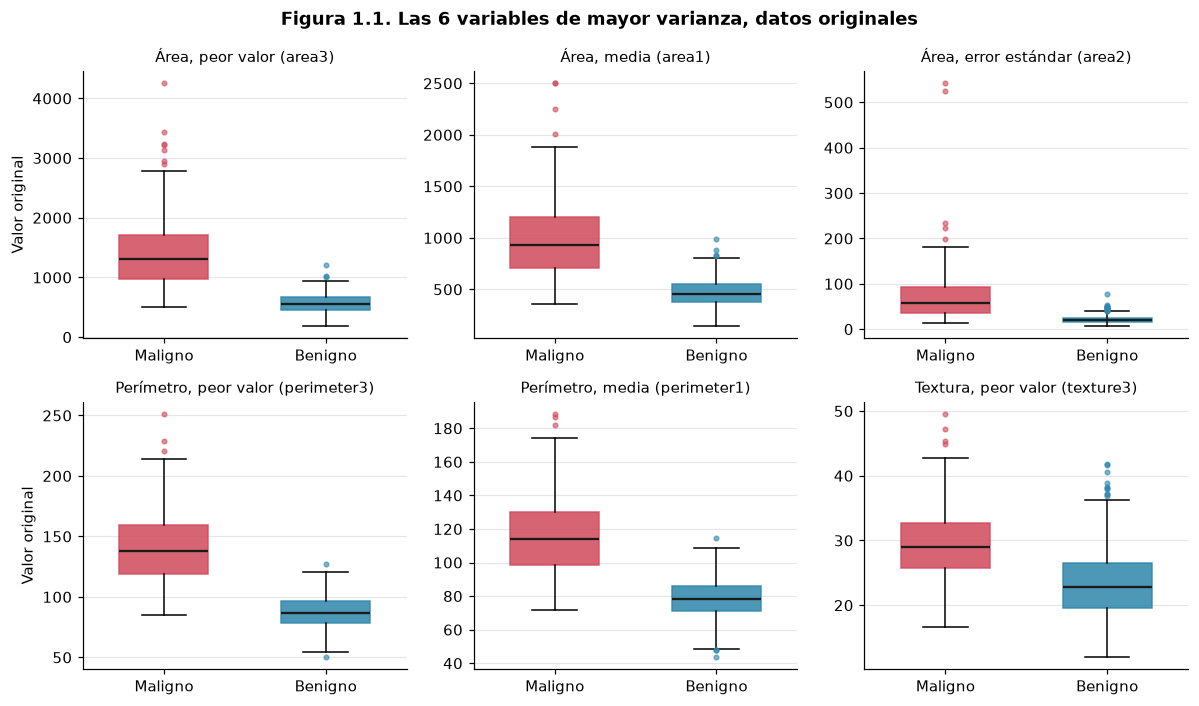

In [8]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Descripción: Selección de las 6 variables de mayor varianza y sus diagramas de caja.
# Insumo:      X, y.
# Resultado:   top_6, Tabla 1.1 y Figura 1.1.
# ===========================================================
# var() calcula la varianza de cada columna; sort_values las ordena, y ascending=False va de mayor a menor
varianzas = X.var().sort_values(ascending=False)
# head(6) toma las 6 primeras; index son sus nombres; tolist() los convierte en una lista
top_6 = varianzas.head(6).index.tolist()

# X[top_6] conserva solo esas 6 columnas; agg calcula varios estadísticos a la vez.
# .T voltea la tabla (filas por columnas), para tener una variable por fila.
resumen_original = X[top_6].agg(["var", "min", "median", "max"]).T
resumen_original.columns = ["Varianza", "Mínimo", "Mediana", "Máximo"]  # Nombres en español
# Agrega dos columnas: la mediana de esas variables calculada solo con Maligno y solo con Benigno
for clase in COLORES_CLASE:
    resumen_original[f"Mediana {clase}"] = X.loc[y == clase, top_6].median()  # Crea la columna con la mediana de esa clase
print("Tabla 1.1. Las 6 variables originales con mayor varianza")  # Título de la tabla
display(resumen_original.round(2))  # round(2) muestra 2 decimales

# Figura de cajas con los datos originales.
# No se pasa compartir_y, así que vale False: cada panel usa su escala, porque son muy distintas.
graficar_cajas(
    X, top_6, y,  # Datos, variables a dibujar y clases
    "Figura 1.1. Las 6 variables de mayor varianza, datos originales",  # Título
    "Valor original", "figura_1.1_cajas_originales.png",  # Nombre del eje y archivo de la imagen
)  # Cierra la llamada a graficar_cajas

### 1b. Estandarización
`StandardScaler` resta a cada variable su media y la divide entre su desviación estándar, `z = (x - media) / desviación`. Se comprueba que las 30 variables queden con media 0 y desviación 1. `StandardScaler` usa la desviación poblacional (`ddof=0`), así que la comprobación usa la misma.

In [9]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Descripción: Comprobación de la estandarización de las 30 variables.
# Insumo:      X_std, feature_names.
# Resultado:   X_std_df (X_std con nombres de columna) y Tabla 1.2.
# ===========================================================
# X_std es un arreglo sin nombres de columna; aquí se pasa a tabla para poder usar los nombres
X_std_df = pd.DataFrame(X_std, columns=feature_names)

# Tabla con la media y la desviación estándar de cada variable.
# ddof=0 es la desviación poblacional (divide entre n), la misma que usa StandardScaler.
comprobacion = pd.DataFrame({"Media": X_std_df.mean(), "Desviación estándar": X_std_df.std(ddof=0)})
# allclose comprueba que todos los valores sean casi iguales al indicado; atol es la tolerancia.
# Se usa porque las computadoras redondean: una media puede salir 0.0000000000001 en lugar de 0.
assert np.allclose(comprobacion["Media"], 0, atol=1e-10)  # Todas las medias deben ser 0
assert np.allclose(comprobacion["Desviación estándar"], 1, atol=1e-10)  # Todas las desviaciones deben ser 1

print("Tabla 1.2. Media y desviación estándar de las 30 variables estandarizadas")  # Título
display(comprobacion.round(4) + 0.0)  # Sumar 0.0 convierte -0.0 en 0.0 al mostrar

Tabla 1.2. Media y desviación estándar de las 30 variables estandarizadas


,Media,Desviación estándar
radius1,0.0,1.0
texture1,0.0,1.0
perimeter1,0.0,1.0
area1,0.0,1.0
smoothness1,0.0,1.0
compactness1,0.0,1.0
concavity1,0.0,1.0
concave_points1,0.0,1.0
symmetry1,0.0,1.0
fractal_dimension1,0.0,1.0


### 1c. Las mismas variables, ya estandarizadas
Se usan **las mismas 6 variables del inciso 1a**. Después de estandarizar, las 30 variables tienen la misma varianza, así que ya no se puede volver a elegir por varianza. Conservarlas permite comparar cada variable antes y después. Aquí todos los paneles comparten el eje vertical, porque ya están en la misma escala.

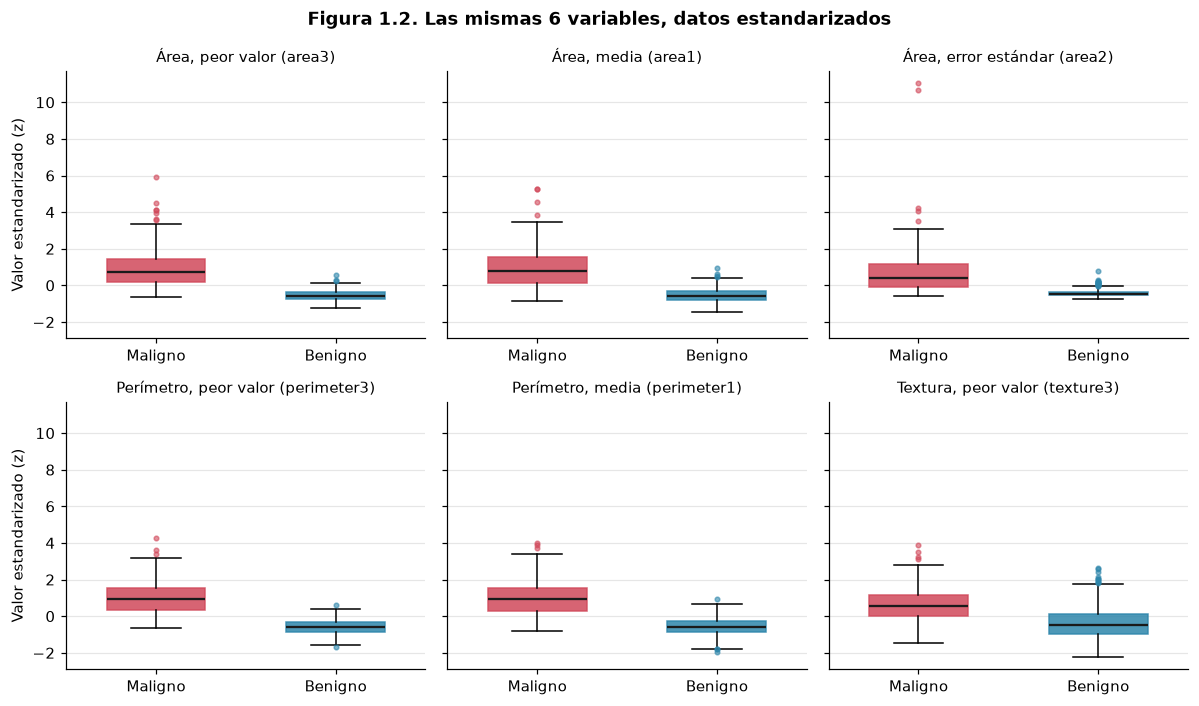

Tabla 1.3. Rango de las 6 variables antes y después de estandarizar


,Rango original,Rango estandarizado,Mínimo estandarizado,Máximo estandarizado
area3,4068.80,7.15,-1.22,5.93
area1,2357.50,6.70,-1.45,5.25
area2,535.40,11.78,-0.74,11.04
perimeter3,200.79,5.98,-1.69,4.29
perimeter1,144.71,5.96,-1.98,3.98
texture3,37.52,6.11,-2.22,3.89


Varianza de area3 entre varianza de la variable con menor varianza (fractal_dimension2): 46,298,438,340 veces
Participación de las 6 variables en la varianza total original: 99.99%


In [10]:
# ===========================================================
# Autor:       Melanie
# Fecha:       02 noviembre 2026
# Descripción: Diagramas de caja de las 6 variables estandarizadas y comparación de escalas.
# Insumo:      X_std_df, top_6, y.
# Resultado:   Tabla 1.3 y Figura 1.2.
# ===========================================================
# Misma figura del inciso 1a, con las mismas 6 variables, pero con los datos estandarizados
graficar_cajas(
    X_std_df, top_6, y,  # Ahora usa la tabla estandarizada
    "Figura 1.2. Las mismas 6 variables, datos estandarizados",  # Título
    "Valor estandarizado (z)", "figura_1.2_cajas_estandarizadas.png",  # Nombre del eje y archivo
    compartir_y=True,  # Misma escala en todos los paneles, porque ya son comparables
)  # Cierra la llamada a graficar_cajas

# Compara el rango (máximo menos mínimo) antes y después de estandarizar.
# Cada clave del diccionario es una columna de la tabla.
resumen_escala = pd.DataFrame({
    "Rango original": X[top_6].max() - X[top_6].min(),  # Rango de los datos originales
    "Rango estandarizado": X_std_df[top_6].max() - X_std_df[top_6].min(),  # Rango de los datos estandarizados
    "Mínimo estandarizado": X_std_df[top_6].min(),  # Desviaciones estándar debajo de la media
    "Máximo estandarizado": X_std_df[top_6].max(),  # Desviaciones estándar arriba de la media
})  # Cierra el diccionario y la creación de la tabla
print("Tabla 1.3. Rango de las 6 variables antes y después de estandarizar")  # Título de la tabla
display(resumen_escala.round(2))  # Muestra la tabla con 2 decimales

# Datos para la interpretación del reporte
# iloc toma por posición: iloc[0] es la varianza mayor, e iloc[-1] la menor (la última de la lista).
# ":,.0f" da formato con comas y sin decimales.
print(f"Varianza de area3 entre varianza de la variable con menor varianza ({varianzas.index[-1]}): "
      f"{varianzas.iloc[0] / varianzas.iloc[-1]:,.0f} veces")  # Divide la varianza mayor entre la menor
# Suma de la varianza de las 6 variables entre la de las 30; ":.2%" lo muestra como porcentaje
print(f"Participación de las 6 variables en la varianza total original: {varianzas.head(6).sum() / varianzas.sum():.2%}")

## Sección 2. PCA
**Responsable:** Magaly

**Propósito:** proyectar los datos estandarizados a un espacio de 3 dimensiones con Análisis de Componentes Principales (PCA), medir cuánta información (varianza) conserva cada componente y cómo se relacionan las variables originales con los nuevos ejes.

**Insumo:** `X_std`, `y`, `feature_names`. **Resultado:** `Z_pca3`, `k95`, Tablas 2.1 a 2.2 y Figuras 2.1 a 2.4.

### 2a. Proyección a 3D y tiempo de transformación
PCA busca las direcciones en las que los datos se dispersan más (componentes principales) y proyecta cada observación sobre las 3 primeras. Se mide solo el tiempo de `fit_transform`, que es la transformación.

In [11]:
# ===========================================================
# Autor:       Magaly
# Fecha:       03 noviembre 2026
# Descripción: Proyección de los datos estandarizados a 3D con PCA y medición del tiempo.
# Insumo:      X_std, y.
# Resultado:   pca_3d, Z_pca3, t_pca3 y Tabla 2.1.
# ===========================================================
# Prepara PCA para conservar solo 3 componentes; todavía no calcula nada.
# random_state fija la semilla por si sklearn usa un método aleatorio internamente.
pca_3d = PCA(n_components=3, random_state=SEED)

# --- MEDICIÓN DEL TIEMPO ---
# perf_counter() da la hora del cronómetro; la diferencia entre dos lecturas es el tiempo transcurrido.
# Solo se mide la transformación, no la impresión ni las gráficas (README, sección 3.4).
t0 = perf_counter()                      # Inicio del cronómetro
Z_pca3 = pca_3d.fit_transform(X_std)     # fit calcula los componentes y transform proyecta los datos
t_pca3 = perf_counter() - t0             # Tiempo total en segundos

# ":.4f" muestra 4 decimales
print(f"Tiempo de transformación con PCA a 3D: {t_pca3:.4f} s")
# shape da (filas, columnas): deben seguir siendo 569 observaciones, ahora con 3 columnas
print(f"Dimensiones antes: {X_std.shape} -> después: {Z_pca3.shape}")

# Registra el tiempo en la tabla comparativa del inciso 5a
comparativa.loc["PCA", "tiempo_s"] = round(t_pca3, 4)

# Tabla con las primeras 5 observaciones ya proyectadas, como evidencia de la transformación.
# Se agrega la clase para ver a qué diagnóstico corresponde cada punto.
tabla_pca3 = pd.DataFrame(Z_pca3, columns=["PC1", "PC2", "PC3"])  # Convierte el arreglo en tabla
tabla_pca3["Clase"] = y.values                                     # values da las etiquetas sin índice
print("Tabla 2.1. Primeras 5 observaciones en el espacio PCA de 3 dimensiones")  # Título
display(tabla_pca3.head().round(4))                                # head() muestra las primeras 5 filas

Tiempo de transformación con PCA a 3D: 0.0006 s
Dimensiones antes: (569, 30) -> después: (569, 3)
Tabla 2.1. Primeras 5 observaciones en el espacio PCA de 3 dimensiones


,PC1,PC2,PC3,Clase
0,9.1928,1.9486,-1.1232,Maligno
1,2.3878,-3.7682,-0.5293,Maligno
2,5.7339,-1.0752,-0.5517,Maligno
3,7.1230,10.2756,-3.2328,Maligno
4,3.9353,-1.9481,1.3898,Maligno


### 2b. Varianza explicada y acumulada por componente
Se ajusta PCA con las 30 componentes para conocer qué porcentaje de la varianza total explica cada una y cuánto se acumula al sumarlas. Se reportan las 10 primeras y se identifica cuántas se necesitan para conservar al menos 95% de la varianza (`k95`), valor que usa la Sección 3.

In [12]:
# ===========================================================
# Autor:       Magaly
# Fecha:       03 noviembre 2026
# Descripción: Varianza explicada y acumulada de los componentes principales y cálculo de k95.
# Insumo:      X_std.
# Resultado:   pca_todas, var_exp, var_acum, k95, Tabla 2.2 y resultados/pca_varianza.csv.
# ===========================================================
# Sin n_components, PCA calcula las 30 componentes posibles (una por variable).
# Se necesitan todas para que la varianza acumulada sea correcta (README, advertencias de PCA).
pca_todas = PCA(random_state=SEED)  # Nombre distinto a pca_completo, que ya se usó en la Sección 0
pca_todas.fit(X_std)                # Solo calcula los componentes; aquí no se necesita proyectar

# explained_variance_ratio_ da la fracción de la varianza total que explica cada componente.
# Multiplicar por 100 la convierte en porcentaje.
var_exp = pca_todas.explained_variance_ratio_ * 100
# cumsum es la suma acumulada: PC1, PC1+PC2, PC1+PC2+PC3, etc.
var_acum = np.cumsum(var_exp)

# Tabla con los 10 primeros componentes; [:10] toma los elementos de la posición 0 a la 9
tabla_varianza = pd.DataFrame({
    "PC": [f"PC{i}" for i in range(1, 11)],         # Nombres PC1 a PC10; range(1, 11) va de 1 a 10
    "Varianza explicada (%)": var_exp[:10],          # Porcentaje de cada componente
    "Varianza acumulada (%)": var_acum[:10],         # Porcentaje acumulado hasta ese componente
})  # Cierra la creación de la tabla
print("Tabla 2.2. Varianza explicada y acumulada de los 10 primeros componentes principales")  # Título
display(tabla_varianza.round(2))  # Muestra con 2 decimales

# --- k95 ---
# var_acum >= 95 da una lista de True/False; argmax da la posición del primer True.
# Se suma 1 porque Python cuenta las posiciones desde 0, pero los componentes desde 1.
k95 = int(np.argmax(var_acum >= 95) + 1)
print(f"k95 = {k95}: los primeros {k95} componentes acumulan {var_acum[k95 - 1]:.2f}% de la varianza")
# Dato para la interpretación: cuánta información conserva la proyección a 3D del inciso 2a
print(f"Las 3 primeras componentes conservan {var_acum[2]:.2f}% de la varianza")

# Exporta la tabla para el tablero (README, sección 3.8); round(4) guarda 4 decimales
exportar_csv(tabla_varianza.round(4), "pca_varianza.csv")

Tabla 2.2. Varianza explicada y acumulada de los 10 primeros componentes principales


,PC,Varianza explicada (%),Varianza acumulada (%)
0,PC1,44.27,44.27
1,PC2,18.97,63.24
2,PC3,9.39,72.64
3,PC4,6.60,79.24
4,PC5,5.50,84.73
5,PC6,4.02,88.76
6,PC7,2.25,91.01
7,PC8,1.59,92.60
8,PC9,1.39,93.99
9,PC10,1.17,95.16


k95 = 10: los primeros 10 componentes acumulan 95.16% de la varianza
Las 3 primeras componentes conservan 72.64% de la varianza


### 2c. Gráfica de varianza explicada y acumulada
Las barras muestran la varianza que explica cada componente y la línea, la varianza acumulada. Se marca el umbral de 95% y el valor `k95`. Las tres primeras barras se resaltan porque corresponden a la proyección 3D del inciso 2a. Ambas series están en porcentaje, por lo que comparten un solo eje vertical.

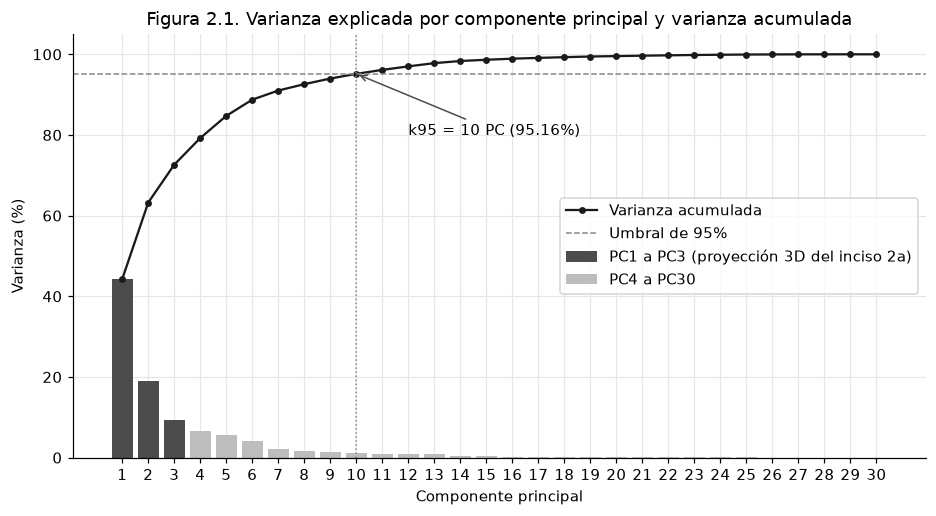

In [13]:
# ===========================================================
# Autor:       Magaly
# Fecha:       03 noviembre 2026
# Descripción: Gráfica de barras de varianza explicada con línea de varianza acumulada.
# Insumo:      var_exp, var_acum, k95.
# Resultado:   Figura 2.1 (figuras/figura_2.1_varianza_pca.png).
# ===========================================================
# arange(1, 31) crea los números 1, 2, ..., 30: la posición de cada componente en el eje x
num_pc = np.arange(1, len(var_exp) + 1)

fig, ax = plt.subplots(figsize=(10, 5))  # Figura de 10 x 5 pulgadas con un solo panel (ax)

# --- BARRAS ---
# Se dibujan en dos grupos para distinguirlos: [:3] son PC1 a PC3 y [3:] son PC4 a PC30.
# Las 3 primeras usan el color fijo de PCA; el resto, un gris claro para que no compitan.
ax.bar(num_pc[:3], var_exp[:3], color=COLORES_METODO["PCA"], label="PC1 a PC3 (proyección 3D del inciso 2a)")
ax.bar(num_pc[3:], var_exp[3:], color="#BDBDBD", label="PC4 a PC30")

# --- LÍNEA DE VARIANZA ACUMULADA ---
# marker="o" pone un punto en cada componente; linewidth es el grosor de la línea
ax.plot(num_pc, var_acum, color="#1A1A1A", marker="o", markersize=3.5, linewidth=1.5,
        label="Varianza acumulada")

# --- UMBRAL DE 95% Y k95 ---
# axhline dibuja una línea horizontal en y = 95; axvline, una vertical en x = k95
ax.axhline(95, color="#888888", linestyle="--", linewidth=1, label="Umbral de 95%")
ax.axvline(k95, color="#888888", linestyle=":", linewidth=1)
# annotate escribe un texto con una flecha: xy es a dónde apunta y xytext dónde va el texto
ax.annotate(f"k95 = {k95} PC ({var_acum[k95 - 1]:.2f}%)",
            xy=(k95, var_acum[k95 - 1]), xytext=(k95 + 2, 80),
            arrowprops={"arrowstyle": "->", "color": "#4C4C4C"})

# --- EJES Y TEXTOS ---
ax.set_xticks(num_pc)                      # Muestra un número por cada componente (1 a 30)
ax.set_xlabel("Componente principal")      # Nombre del eje x
ax.set_ylabel("Varianza (%)")              # Nombre del eje y; las dos series están en porcentaje
ax.set_ylim(0, 105)                        # El eje y va de 0 a 105 para que se vea el 100%
ax.set_title("Figura 2.1. Varianza explicada por componente principal y varianza acumulada")
ax.legend(loc="center right")              # Leyenda a la derecha, donde las barras ya son bajas

fig.savefig(RUTA_FIGURAS / "figura_2.1_varianza_pca.png")  # Guarda la imagen para el reporte
plt.show()                                                  # Muestra la figura en el notebook

### 2d. Círculo de correlaciones
Cada flecha representa una variable original y sus coordenadas son su correlación con dos componentes principales. Una flecha cercana al borde del círculo indica que la variable está bien representada en ese plano, y flechas que apuntan en la misma dirección indican variables correlacionadas entre sí. Se grafican PC1 contra PC2 y PC1 contra PC3. Para que el texto sea legible, solo se etiquetan las 6 flechas más largas con direcciones distintas; los 30 valores están en la Tabla 2.3.

Tabla 2.3. Correlación de las 30 variables con los 3 primeros componentes principales


,PC1,PC2,PC3
radius1,0.80,-0.56,-0.01
texture1,0.38,-0.14,0.11
perimeter1,0.83,-0.51,-0.02
area1,0.81,-0.55,0.05
smoothness1,0.52,0.44,-0.18
compactness1,0.87,0.36,-0.12
concavity1,0.94,0.14,0.00
concave_points1,0.95,-0.08,-0.04
symmetry1,0.50,0.45,-0.07
fractal_dimension1,0.23,0.87,-0.04


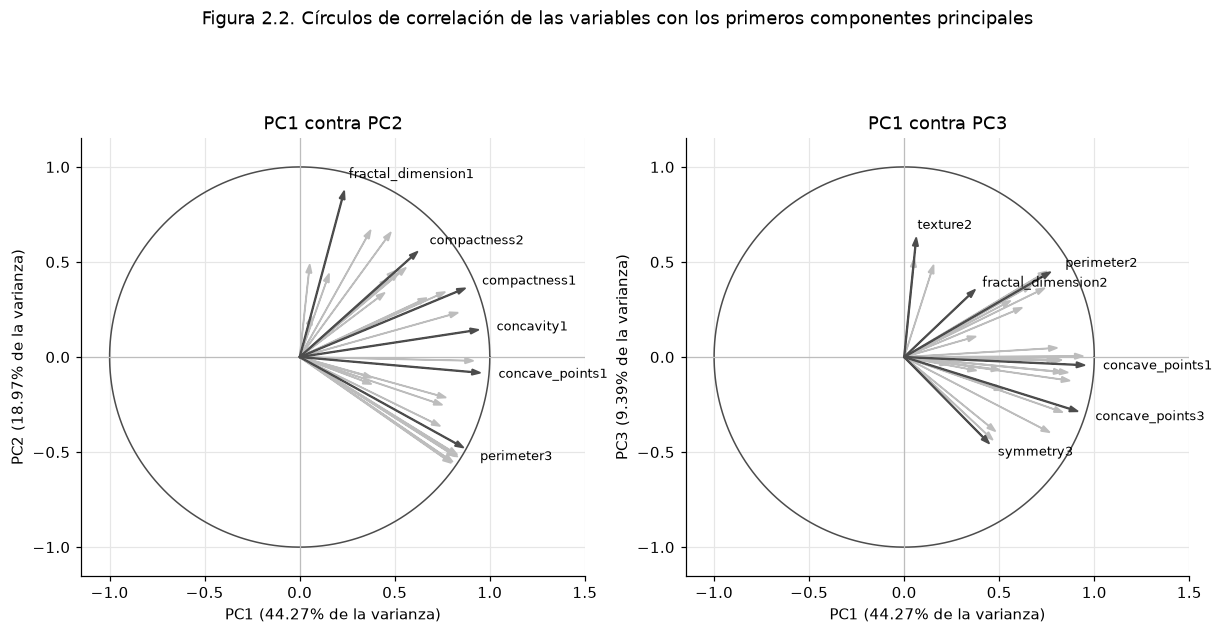

In [14]:
# ===========================================================
# Autor:       Magaly
# Fecha:       03 noviembre 2026
# Descripción: Correlación de cada variable con los 3 primeros PC y círculos de correlación.
# Insumo:      X_std, Z_pca3, feature_names, var_exp.
# Resultado:   correlaciones, Tabla 2.3 y Figura 2.2 (figuras/figura_2.2_circulo_correlaciones.png).
# ===========================================================
# --- CORRELACIONES ---
# Correlación de Pearson entre cada variable original (estandarizada) y cada componente.
# Va de -1 a 1: cerca de 1, la variable crece cuando el PC crece; cerca de -1, crece cuando el PC baja.
nombres_pc = ["PC1", "PC2", "PC3"]
# Tabla vacía: una fila por variable y una columna por PC; se llena con el ciclo de abajo
correlaciones = pd.DataFrame(index=feature_names, columns=nombres_pc, dtype=float)
for j, variable in enumerate(feature_names):   # enumerate da la posición (j) y el nombre de cada variable
    for i, pc in enumerate(nombres_pc):         # Recorre PC1, PC2 y PC3
        # corrcoef regresa una matriz de 2 x 2; el valor [0, 1] es la correlación entre las dos series
        correlaciones.loc[variable, pc] = np.corrcoef(X_std[:, j], Z_pca3[:, i])[0, 1]

print("Tabla 2.3. Correlación de las 30 variables con los 3 primeros componentes principales")
display(correlaciones.round(2))  # Evidencia completa: incluye las variables sin etiqueta en la figura


def graficar_circulo(ax, pc_x, pc_y):  # Recibe el panel y los nombres de los dos PC a comparar
    """Dibuja el círculo de correlación de las 30 variables para dos componentes."""
    x = correlaciones[pc_x].values  # Correlación de cada variable con el PC del eje x
    y_ = correlaciones[pc_y].values  # Con el PC del eje y (y_ para no confundir con las clases y)

    # Círculo unitario: ninguna flecha puede salir de él, porque una correlación no pasa de 1
    angulos = np.linspace(0, 2 * np.pi, 200)  # 200 ángulos de 0 a 360 grados (en radianes)
    ax.plot(np.cos(angulos), np.sin(angulos), color=COLORES_METODO["PCA"], linewidth=1)
    ax.axhline(0, color="#BDBDBD", linewidth=0.8)  # Eje horizontal en 0
    ax.axvline(0, color="#BDBDBD", linewidth=0.8)  # Eje vertical en 0

    # --- VARIABLES QUE SE ETIQUETAN ---
    # 30 nombres se enciman, así que solo se etiquetan 6: las flechas más largas
    # (mejor representadas en este plano) que apunten en direcciones distintas.
    largo = np.hypot(x, y_)                     # Largo de cada flecha: raíz de (x² + y²)
    angulo = np.degrees(np.arctan2(y_, x))      # Dirección de cada flecha en grados
    etiquetadas = []                            # Aquí se guardan las posiciones elegidas
    for j in np.argsort(largo)[::-1]:           # argsort ordena de menor a mayor; [::-1] lo invierte
        # Se elige solo si su dirección se separa al menos 12 grados de las ya elegidas
        if all(abs(angulo[j] - angulo[k]) >= 12 for k in etiquetadas):
            etiquetadas.append(j)
        if len(etiquetadas) == 6:               # Al llegar a 6 se detiene
            break

    # --- FLECHAS ---
    for j in range(len(feature_names)):         # Una flecha por variable, desde el origen (0, 0)
        destacada = j in etiquetadas            # True si esta variable lleva etiqueta
        ax.arrow(0, 0, x[j], y_[j], length_includes_head=True, head_width=0.03,
                 width=0.004 if destacada else 0.002,                       # Más gruesa si se etiqueta
                 color=COLORES_METODO["PCA"] if destacada else "#BDBDBD",  # Oscura o gris claro
                 zorder=3 if destacada else 2)                              # zorder: las oscuras van encima
    for j in etiquetadas:  # El texto va un poco más allá de la punta (1.1 veces)
        ax.text(x[j] * 1.1, y_[j] * 1.1, feature_names[j], fontsize=8.5, va="center",
                ha="left" if x[j] >= 0 else "right")  # Alinea el texto hacia afuera del círculo

    # --- EJES ---
    ax.set_xlim(-1.15, 1.5)   # Espacio extra a la derecha para los nombres
    ax.set_ylim(-1.15, 1.15)
    ax.set_aspect("equal")    # Misma escala en x y y, para que el círculo no se vea ovalado
    # El porcentaje de varianza de cada PC indica cuánto pesa ese eje
    ax.set_xlabel(f"{pc_x} ({var_exp[nombres_pc.index(pc_x)]:.2f}% de la varianza)")
    ax.set_ylabel(f"{pc_y} ({var_exp[nombres_pc.index(pc_y)]:.2f}% de la varianza)")
    ax.set_title(f"{pc_x} contra {pc_y}")


# Dos paneles lado a lado: PC1 contra PC2 y PC1 contra PC3
fig, (ax_izq, ax_der) = plt.subplots(1, 2, figsize=(13, 6.5))
graficar_circulo(ax_izq, "PC1", "PC2")
graficar_circulo(ax_der, "PC1", "PC3")
fig.suptitle("Figura 2.2. Círculos de correlación de las variables con los primeros componentes principales")
fig.savefig(RUTA_FIGURAS / "figura_2.2_circulo_correlaciones.png")  # Guarda la imagen para el reporte
plt.show()

### 2e. Espacio de 3 dimensiones de PCA
Se grafican las 569 observaciones en el espacio formado por PC1, PC2 y PC3, con un color por clase: rojo para maligno y azul para benigno.

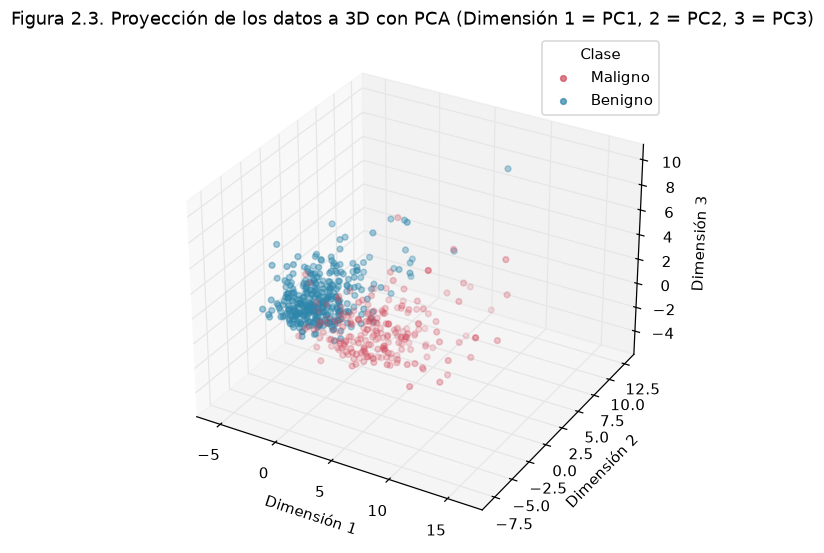

In [15]:
# ===========================================================
# Autor:       Magaly
# Fecha:       03 noviembre 2026
# Descripción: Dispersión 3D de la proyección PCA, con un color por clase.
# Insumo:      Z_pca3, y.
# Resultado:   Figura 2.3 (figuras/figura_2.3.png).
# ===========================================================
# graficar_3d es la función compartida de la Sección 0: usa COLORES_CLASE y guarda la imagen.
# Recibe la proyección, las clases, el título y el número de figura.
# En esta figura, Dimensión 1, 2 y 3 corresponden a PC1, PC2 y PC3.
graficar_3d(Z_pca3, y, "Proyección de los datos a 3D con PCA (Dimensión 1 = PC1, 2 = PC2, 3 = PC3)", "2.3")

### 2f. Error de reconstrucción contra el número de componentes
Para cada k de 1 a 30 se proyectan los datos a k componentes y se reconstruyen en el espacio original de 30 variables con `inverse_transform`. El error de reconstrucción es el error cuadrático medio (MSE) entre los datos estandarizados y su reconstrucción. Se marcan k = 3, usado en la proyección 3D, y `k95`.

Tabla 2.4. Error de reconstrucción de PCA para valores representativos de k


,k,MSE
0,1,0.5573
1,2,0.3676
2,3,0.2736
4,5,0.1527
9,10,0.0484
19,20,0.0044
29,30,0.0000


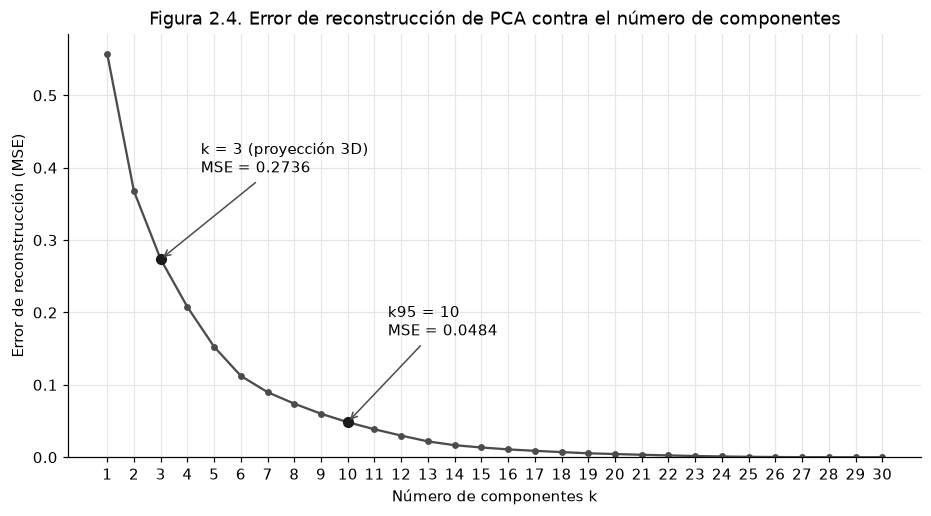

In [16]:
# ===========================================================
# Autor:       Magaly
# Fecha:       03 noviembre 2026
# Descripción: Error de reconstrucción (MSE) de PCA contra el número de componentes k.
# Insumo:      X_std, k95.
# Resultado:   tabla_error_rec, Tabla 2.4, Figura 2.4 y resultados/pca_error_reconstruccion.csv.
# ===========================================================
# Para cada k de 1 a 30: se proyecta a k dimensiones, se regresa a las 30 variables
# (inverse_transform) y se mide cuánto se alejó la reconstrucción de los datos reales.
filas = []                                  # Aquí se guarda un par (k, MSE) por cada k
for k in range(1, X_std.shape[1] + 1):      # range(1, 31) recorre k = 1, 2, ..., 30
    pca_k = PCA(n_components=k, random_state=SEED)       # PCA que conserva k componentes
    Z_k = pca_k.fit_transform(X_std)                     # Proyección a k dimensiones
    X_rec = pca_k.inverse_transform(Z_k)                 # Regreso al espacio de 30 variables
    # error_reconstruccion es la función compartida de la Sección 0 (MSE)
    filas.append({"k": k, "MSE": error_reconstruccion(X_std, X_rec)})
tabla_error_rec = pd.DataFrame(filas)       # Convierte la lista en tabla: columnas k y MSE

# Tabla con algunos valores representativos, como evidencia
print("Tabla 2.4. Error de reconstrucción de PCA para valores representativos de k")
# isin conserva solo las filas cuyo k esté en la lista
display(tabla_error_rec[tabla_error_rec["k"].isin([1, 2, 3, 5, 10, 20, 30])].round(4))

# --- GRÁFICA ---
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(tabla_error_rec["k"], tabla_error_rec["MSE"], color=COLORES_METODO["PCA"],
        marker="o", markersize=3.5, linewidth=1.5)
# Marca los dos valores de k que se usan en la práctica: 3 (proyección 3D) y k95
for k_marcado, texto in [(3, "k = 3 (proyección 3D)"), (k95, f"k95 = {k95}")]:
    # Busca la fila de ese k y toma su MSE; iloc[0] saca el único valor encontrado
    mse_k = tabla_error_rec.loc[tabla_error_rec["k"] == k_marcado, "MSE"].iloc[0]
    ax.scatter(k_marcado, mse_k, color="#1A1A1A", s=40, zorder=3)  # Punto más grande y oscuro
    # "\n" es un salto de línea dentro del texto
    ax.annotate(f"{texto}\nMSE = {mse_k:.4f}", xy=(k_marcado, mse_k),
                xytext=(k_marcado + 1.5, mse_k + 0.12),       # El texto va arriba a la derecha
                arrowprops={"arrowstyle": "->", "color": "#4C4C4C"})
ax.set_xticks(tabla_error_rec["k"])          # Un número por cada k
ax.set_xlabel("Número de componentes k")
ax.set_ylabel("Error de reconstrucción (MSE)")
ax.set_ylim(bottom=0)                        # El eje empieza en 0, el error mínimo posible
ax.set_title("Figura 2.4. Error de reconstrucción de PCA contra el número de componentes")
fig.savefig(RUTA_FIGURAS / "figura_2.4_error_reconstruccion_pca.png")
plt.show()

# Exporta la curva completa para el tablero (README, sección 3.8)
exportar_csv(tabla_error_rec, "pca_error_reconstruccion.csv")

### Métricas de PCA para la tabla comparativa (inciso 5a)
Se calculan sobre la proyección 3D del inciso 2a, con las funciones compartidas de la Sección 0 para que sean comparables con los demás métodos: stress de Sammon respecto a `X_std` (30 dimensiones), exactitud de k-NN y error de reconstrucción con k = 3. Se exporta además la proyección 3D para el tablero.

In [17]:
# ===========================================================
# Autor:       Magaly
# Fecha:       03 noviembre 2026
# Descripción: Métricas de la proyección PCA 3D para la tabla 5a y exportación de resultados.
# Insumo:      X_std, Z_pca3, y, t_pca3, tabla_error_rec.
# Resultado:   Tabla 2.5, fila PCA de comparativa y resultados/pca_3d.csv.
# ===========================================================
# Stress de Sammon: cuánto se deformaron las distancias entre pacientes al pasar de 30D a 3D
stress_pca3 = stress_sammon(X_std, Z_pca3)
# k-NN: qué tan bien se distinguen las clases en el espacio 3D (media y desviación de 5 particiones)
knn_media_pca3, knn_std_pca3 = evaluar_knn(Z_pca3, y)
# Error de reconstrucción con k = 3, ya calculado en el inciso 2f; se toma de la tabla
mse_pca3 = tabla_error_rec.loc[tabla_error_rec["k"] == 3, "MSE"].iloc[0]

# --- REGISTRO EN LA TABLA COMPARATIVA ---
# .loc[fila, columna] = valor; round(4) deja 4 decimales, como acordó el equipo
comparativa.loc["PCA", "stress_sammon"] = round(stress_pca3, 4)
comparativa.loc["PCA", "knn_exactitud_media"] = round(knn_media_pca3, 4)
comparativa.loc["PCA", "knn_exactitud_std"] = round(knn_std_pca3, 4)
comparativa.loc["PCA", "error_reconstruccion_mse"] = round(mse_pca3, 4)
comparativa.loc["PCA", "notas"] = "3 componentes; stress contra X_std (30D); MSE en el espacio estandarizado"

# Tabla de evidencia con las 4 métricas de PCA
metricas_pca = pd.DataFrame({
    "Métrica": ["Tiempo de transformación (s)", "Stress de Sammon (contra X_std)",
                "Exactitud k-NN (media)", "Exactitud k-NN (desviación)", "Error de reconstrucción (MSE)"],
    "Valor": [t_pca3, stress_pca3, knn_media_pca3, knn_std_pca3, mse_pca3],
})  # Cierra la creación de la tabla
print("Tabla 2.5. Métricas de la proyección PCA a 3 dimensiones")
display(metricas_pca.round(4))

# --- EXPORTACIÓN ---
# Proyección 3D con la clase de cada punto, para graficarla en el tablero
exportar_csv(tabla_pca3, "pca_3d.csv")  # tabla_pca3 se creó en el inciso 2a (PC1, PC2, PC3, Clase)

Tabla 2.5. Métricas de la proyección PCA a 3 dimensiones


,Métrica,Valor
0,Tiempo de transformación (s),0.0006
1,Stress de Sammon (contra X_std),0.0593
2,Exactitud k-NN (media),0.9332
3,Exactitud k-NN (desviación),0.0226
4,Error de reconstrucción (MSE),0.2736


## Sección 3. Sammon
**Responsables:** Ricardo (incisos 3a a 3f) y Melanie (incisos 3g a 3i)

**Propósito:** proyectar los datos estandarizados a 3 dimensiones con el mapeo de Sammon, directamente y después de reducirlos con PCA, medir qué tan parecidas son ambas proyecciones y ver cómo cambian los resultados con el número k de componentes de PCA.

**Insumo:** `X_std`, `y`, `k95`. **Resultado:** `Z_sammon`, `Z_sammon_pca`, `barrido_k`, Tablas 3.1 a 3.8 y Figuras 3.1 a 3.6.

Se usa la función de Tom Pollard proporcionada en el documento de la práctica (https://github.com/tompollard/sammon), adaptada para guardar el stress de cada iteración, que se necesita para la curva del inciso 3a. Para que la semilla fija tenga efecto, Sammon inicia desde una configuración aleatoria (`init="random"`) y se fija `np.random.seed(SEED)` antes de cada corrida.

In [18]:
# ===========================================================
# Autor:       Ricardo
# Fecha:       04 noviembre 2026
# Descripción: Librerías adicionales y parámetros de Sammon para toda la Sección 3.
# Insumo:      ninguno.
# Resultado:   PARAMS_SAMMON (lo usan los incisos 3a a 3i).
# ===========================================================
from scipy.spatial import procrustes            # Análisis de Procrustes (inciso 3f)
from scipy.spatial.distance import cdist        # Matriz de distancias entre todos los pares de puntos

# Parámetros de Sammon. Se definen una sola vez para que todos los incisos usen los mismos.
PARAMS_SAMMON = {
    "n": 3,              # Dimensiones de salida
    "init": "random",    # Inicio aleatorio, para que la semilla sí tenga efecto
    "maxiter": 500,      # Máximo de iteraciones (valor por defecto de la librería)
    "tolfun": 1e-9,      # Se detiene cuando el stress casi no cambia entre iteraciones
    "maxhalves": 20,     # Máximo de veces que se reduce el paso a la mitad en una iteración
}  # Cierra el diccionario de parámetros

In [19]:
# ===========================================================
# Autor:       Ricardo (adaptación)
# Fecha:       04 noviembre 2026
# Descripción: Función de Sammon adaptada para guardar el stress de cada iteración.
#              Fuente: Tom J. Pollard, https://github.com/tompollard/sammon (sammon.py, 2014),
#              portada del código de MATLAB de G. C. Cawley y N. L. C. Talbot. Licencia GNU GPL v2.
#              Los cambios están marcados con [ADAPTACIÓN].
# Insumo:      ninguno.
# Resultado:   función sammon_adaptado.
# ===========================================================


def sammon_adaptado(x, n, display=0, maxhalves=20, maxiter=500, tolfun=1e-9, init="pca"):  # Recibe los datos, las dimensiones de salida y las opciones
    """Mapeo de Sammon de x a n dimensiones. Regresa la proyección, el stress final
    y la lista con el stress de cada iteración."""
    # --- DISTANCIAS DE ENTRADA ---
    D = cdist(x, x)    # Matriz N x N con la distancia entre cada par de puntos de entrada
    N = x.shape[0]     # Número de puntos
    scale = 0.5 / D.sum()  # Normalización del stress que usa la librería
    D = D + np.eye(N)  # eye pone 1 en la diagonal; evita dividir entre 0
    if np.count_nonzero(D <= 0) > 0:  # Dos puntos iguales tendrían distancia 0
        raise ValueError("Hay distancias menores o iguales a 0 (¿filas duplicadas?)")
    Dinv = 1 / D  # Inverso de cada distancia de entrada

    # --- CONFIGURACIÓN INICIAL ---
    if init == "pca":  # Inicio con las primeras n componentes principales
        UU, DD, _ = np.linalg.svd(x)
        y = UU[:, :n] * DD[:n]
    else:  # Inicio aleatorio: depende de np.random.seed
        y = np.random.normal(0.0, 1.0, [N, n])

    one = np.ones([N, n])            # Matriz de unos; sirve para sumar por filas
    d = cdist(y, y) + np.eye(N)      # Distancias en la proyección
    dinv = 1. / d
    delta = D - d                    # Diferencia entre distancias de entrada y de la proyección
    E = ((delta ** 2) * Dinv).sum()  # Stress sin normalizar
    historial_stress = [E * scale]   # [ADAPTACIÓN] la posición 0 guarda el stress inicial

    # --- OPTIMIZACIÓN ---
    for i in range(maxiter):  # Cada vuelta es una iteración
        # Gradiente (g) y diagonal del Hessiano (H): indican hacia dónde y cuánto mover cada punto
        delta = dinv - Dinv
        deltaone = np.dot(delta, one)
        g = np.dot(delta, y) - (y * deltaone)
        dinv3 = dinv ** 3
        y2 = y ** 2
        H = np.dot(dinv3, y2) - deltaone - np.dot(2, y) * np.dot(dinv3, y) + y2 * np.dot(dinv3, one)
        s = -g.flatten(order="F") / np.abs(H.flatten(order="F"))  # Paso de Newton
        y_old = y  # Guarda la posición actual por si hay que reducir el paso

        # Si el paso empeora el stress, se reduce a la mitad hasta que mejore
        for j in range(maxhalves):
            s_reshape = np.reshape(s, (-1, n), order="F")
            y = y_old + s_reshape
            d = cdist(y, y) + np.eye(N)
            dinv = 1 / d
            delta = D - d
            E_new = ((delta ** 2) * Dinv).sum()
            if E_new < E:   # Si mejoró, se acepta el paso
                break
            else:
                s = 0.5 * s  # Si no, el paso se reduce a la mitad

        if j == maxhalves - 1:
            print("Aviso: se excedió maxhalves; Sammon puede no converger.")

        historial_stress.append(E_new * scale)  # [ADAPTACIÓN] stress de la iteración i + 1

        # Criterio de paro: el cambio relativo del stress es menor que la tolerancia
        if abs((E - E_new) / E) < tolfun:
            if display:
                print("Se alcanzó la tolerancia: termina la optimización.")
            break

        E = E_new
        if display > 1:
            print(f"Iteración {i + 1}: stress = {E * scale:.10f}")

    if i == maxiter - 1:
        print("Aviso: se alcanzó maxiter; Sammon puede no haber convergido.")

    E = E * scale  # Stress final normalizado
    return y, E, historial_stress  # [ADAPTACIÓN] también regresa el historial

In [20]:
# ===========================================================
# Autor:       Ricardo
# Fecha:       04 noviembre 2026
# Descripción: Funciones para ejecutar Sammon con semilla fija y medir su tiempo.
# Insumo:      sammon_adaptado, PARAMS_SAMMON, SEED.
# Resultado:   funciones ejecutar_sammon y pca_mas_sammon (esta última la usan 3g a 3i).
# ===========================================================


def ejecutar_sammon(Z_entrada):  # Recibe los datos que se van a proyectar
    """Fija la semilla, corre Sammon y mide solo el tiempo de la transformación."""
    np.random.seed(SEED)  # Misma semilla antes de cada corrida: mismo inicio aleatorio
    t0 = perf_counter()   # Inicio del cronómetro
    # ** desempaca el diccionario: equivale a escribir n=3, init="random", ...
    Z, stress_lib, historial = sammon_adaptado(Z_entrada, **PARAMS_SAMMON)
    t = perf_counter() - t0  # Tiempo en segundos
    return {"Z": Z, "t_sammon": t, "stress_libreria": stress_lib, "historial": historial}


def pca_mas_sammon(X_std, k):  # Recibe los datos estandarizados y el número de componentes k
    """Incisos 3c + 3d para cualquier k: PCA a k dimensiones y Sammon a 3D sobre el resultado."""
    pca_k_sammon = PCA(n_components=k, random_state=SEED)  # PCA con k componentes
    t0 = perf_counter()
    Z_pca = pca_k_sammon.fit_transform(X_std)  # Proyección a k dimensiones
    t_pca = perf_counter() - t0
    r = ejecutar_sammon(Z_pca)  # Sammon sobre el resultado del PCA
    return {"t_pca": t_pca, "t_sammon": r["t_sammon"], "t_total": t_pca + r["t_sammon"],
            "Z": r["Z"], "Z_pca": Z_pca, "historial": r["historial"],
            "stress_libreria": r["stress_libreria"],        # Respecto a su entrada (k dimensiones)
            "stress_xstd": stress_sammon(X_std, r["Z"])}   # Respecto a X_std (30 dimensiones)

### 3a. Proyección a 3D con Sammon y curva de stress
Se aplica Sammon a `X_std` con la semilla fija y se mide el tiempo total de la transformación. La curva muestra el stress después de cada iteración; el eje vertical está en escala logarítmica porque el stress baja varios órdenes de magnitud.

In [21]:
# ===========================================================
# Autor:       Ricardo
# Fecha:       04 noviembre 2026
# Descripción: Proyección de los datos estandarizados a 3D con Sammon y medición del tiempo.
# Insumo:      X_std.
# Resultado:   res_sammon, Z_sammon, t_sammon_directo, stress_libreria_directo y Tabla 3.1.
# ===========================================================
res_sammon = ejecutar_sammon(X_std)  # Corre Sammon; regresa un diccionario con los resultados

Z_sammon = res_sammon["Z"]                                # Proyección 3D
t_sammon_directo = res_sammon["t_sammon"]                 # Tiempo total del inciso 3a
stress_libreria_directo = res_sammon["stress_libreria"]   # Stress final; lo usa Melanie en 3g a 3i

tiempo_3a = pd.DataFrame(
    [("Tiempo total de la transformación (s)", round(t_sammon_directo, 4))],
    columns=["Resultado", "Valor"],
)  # Cierra la creación de la tabla
print("Tabla 3.1. Tiempo de la transformación a 3 dimensiones con Sammon (inciso 3a)")
display(tiempo_3a)

Tabla 3.1. Tiempo de la transformación a 3 dimensiones con Sammon (inciso 3a)


,Resultado,Valor
0,Tiempo total de la transformación (s),1.2606


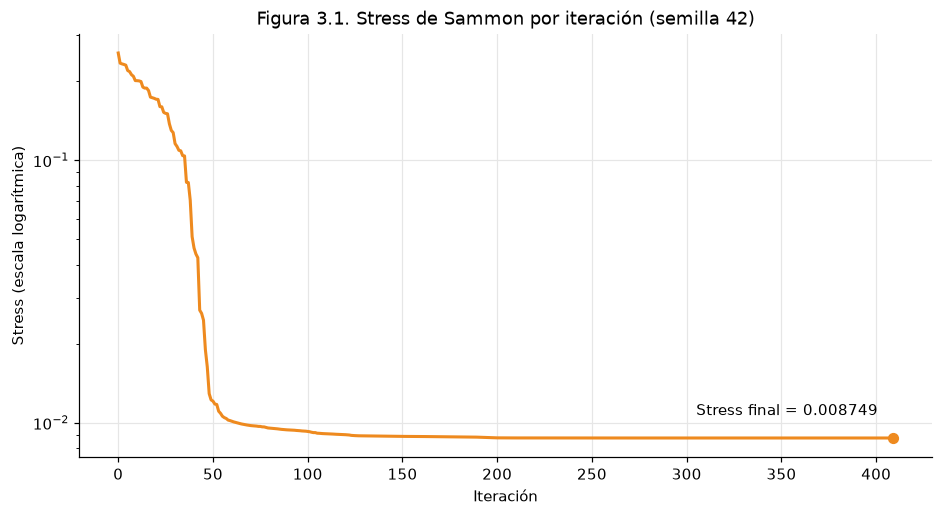

In [22]:
# ===========================================================
# Autor:       Ricardo
# Fecha:       04 noviembre 2026
# Descripción: Curva de stress por iteración de Sammon y su exportación.
# Insumo:      res_sammon.
# Resultado:   Figura 3.1 y resultados/sammon_stress_iteraciones.csv.
# ===========================================================
historial_sammon_directo = res_sammon["historial"]          # Stress de cada iteración
iteraciones_3a = np.arange(len(historial_sammon_directo))   # 0, 1, 2, ...; 0 es el inicio aleatorio

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(iteraciones_3a, historial_sammon_directo, color=COLORES_METODO["Sammon"], linewidth=2)
ax.set_yscale("log")  # Escala logarítmica: cada marca del eje vale 10 veces la anterior
# Punto y texto en el stress final
ax.scatter(iteraciones_3a[-1], historial_sammon_directo[-1], color=COLORES_METODO["Sammon"], s=40, zorder=3)
ax.annotate(f"Stress final = {historial_sammon_directo[-1]:.6f}",
            xy=(iteraciones_3a[-1], historial_sammon_directo[-1]),
            xytext=(-10, 15), textcoords="offset points", ha="right")
ax.set_xlabel("Iteración")
ax.set_ylabel("Stress (escala logarítmica)")
ax.set_title(f"Figura 3.1. Stress de Sammon por iteración (semilla {SEED})")
fig.savefig(RUTA_FIGURAS / "figura_3.1_stress_sammon.png")  # Guarda la imagen para el reporte
plt.show()

# Exporta el historial para el tablero (README, sección 3.8)
exportar_csv(pd.DataFrame({"iteracion": iteraciones_3a, "stress": historial_sammon_directo}),
             "sammon_stress_iteraciones.csv")

### 3b. Espacio de 3 dimensiones de Sammon
Se grafican las 569 observaciones en el espacio calculado en el inciso 3a, con un color por clase.

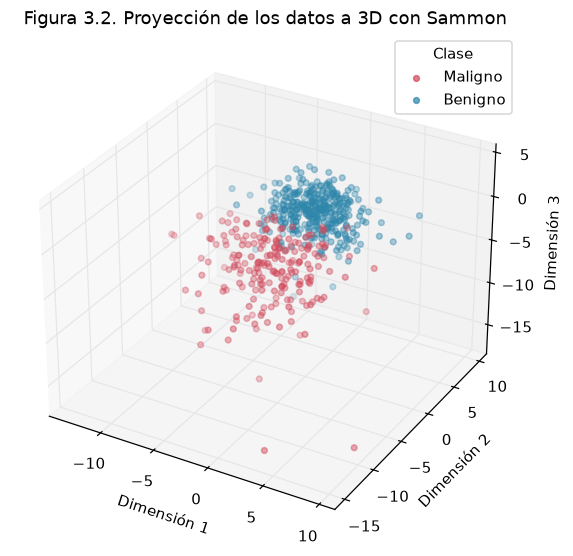

In [23]:
# ===========================================================
# Autor:       Ricardo
# Fecha:       04 noviembre 2026
# Descripción: Dispersión 3D de la proyección de Sammon y su exportación.
# Insumo:      Z_sammon, y.
# Resultado:   Figura 3.2 (figuras/figura_3.2.png) y resultados/sammon_3d.csv.
# ===========================================================
# graficar_3d es la función compartida de la Sección 0: usa COLORES_CLASE y guarda la imagen
graficar_3d(Z_sammon, y, "Proyección de los datos a 3D con Sammon", "3.2")

# Proyección con la clase de cada punto, para el tablero
tabla_sammon_3d = pd.DataFrame(Z_sammon, columns=["dim1", "dim2", "dim3"])
tabla_sammon_3d["Clase"] = y.values  # values da las etiquetas sin índice
exportar_csv(tabla_sammon_3d, "sammon_3d.csv")

### 3c. PCA a k dimensiones con al menos 95% de la varianza
Con base en el inciso 2b, se transforman los datos estandarizados con PCA a `k95` dimensiones y se mide el tiempo de `fit_transform`.

In [24]:
# ===========================================================
# Autor:       Ricardo
# Fecha:       04 noviembre 2026
# Descripción: Transformación de X_std a k95 dimensiones con PCA y medición del tiempo.
# Insumo:      X_std, k95, var_acum.
# Resultado:   Z_pca_k95, t_pca_k95 y Tabla 3.2.
# ===========================================================
pca_k95 = PCA(n_components=k95, random_state=SEED)  # PCA con k95 componentes

t0 = perf_counter()                          # Inicio del cronómetro
Z_pca_k95 = pca_k95.fit_transform(X_std)     # Proyección a k95 dimensiones
t_pca_k95 = perf_counter() - t0              # Tiempo en segundos

resultados_3c = pd.DataFrame(
    [
        ("Componentes (k95)", k95),
        ("Varianza acumulada (%)", round(var_acum[k95 - 1], 2)),  # var_acum viene del inciso 2b
        ("Tiempo de la transformación (s)", round(t_pca_k95, 4)),
    ],
    columns=["Resultado", "Valor"],
    dtype=object,  # object conserva cada valor con su propio formato (entero, decimal)
)  # Cierra la creación de la tabla
print(f"Tabla 3.2. Transformación con PCA a k95 = {k95} dimensiones (inciso 3c)")
display(resultados_3c)

Tabla 3.2. Transformación con PCA a k95 = 10 dimensiones (inciso 3c)


,Resultado,Valor
0,Componentes (k95),10
1,Varianza acumulada (%),95.16
2,Tiempo de la transformación (s),0.0005


### 3d. Sammon sobre el resultado de PCA
Se aplica Sammon, con la misma semilla del inciso 3a, a los datos del inciso 3c para proyectarlos a 3D, y se mide el tiempo de la transformación.

In [25]:
# ===========================================================
# Autor:       Ricardo
# Fecha:       04 noviembre 2026
# Descripción: Proyección a 3D con Sammon de los datos del inciso 3c y medición del tiempo.
# Insumo:      Z_pca_k95.
# Resultado:   res_sammon_pca, Z_sammon_pca, t_sammon_pca y Tabla 3.3.
# ===========================================================
res_sammon_pca = ejecutar_sammon(Z_pca_k95)  # Misma función y misma semilla que en el inciso 3a

Z_sammon_pca = res_sammon_pca["Z"]          # Proyección 3D
t_sammon_pca = res_sammon_pca["t_sammon"]   # Tiempo de la transformación

tiempo_3d = pd.DataFrame(
    [("Tiempo de la transformación (s)", round(t_sammon_pca, 4))],
    columns=["Resultado", "Valor"],
)  # Cierra la creación de la tabla
print(f"Tabla 3.3. Tiempo de la transformación a 3D con Sammon sobre PCA, k = {k95} (inciso 3d)")
display(tiempo_3d)

Tabla 3.3. Tiempo de la transformación a 3D con Sammon sobre PCA, k = 10 (inciso 3d)


,Resultado,Valor
0,Tiempo de la transformación (s),1.3071


### 3e. Espacio de 3 dimensiones de Sammon sobre PCA
Se grafican las 569 observaciones en el espacio calculado en el inciso 3d, con un color por clase.

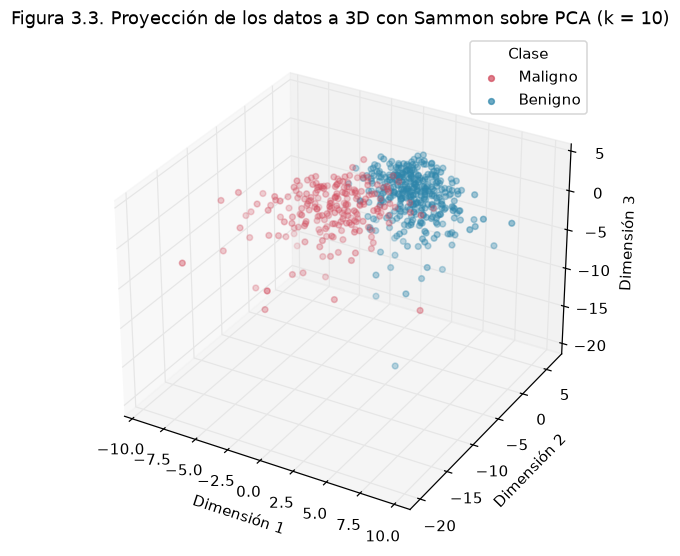

In [26]:
# ===========================================================
# Autor:       Ricardo
# Fecha:       04 noviembre 2026
# Descripción: Dispersión 3D de la proyección de Sammon sobre PCA y su exportación.
# Insumo:      Z_sammon_pca, y, k95.
# Resultado:   Figura 3.3 (figuras/figura_3.3.png) y resultados/sammon_pca_3d.csv.
# ===========================================================
graficar_3d(Z_sammon_pca, y, f"Proyección de los datos a 3D con Sammon sobre PCA (k = {k95})", "3.3")

tabla_sammon_pca_3d = pd.DataFrame(Z_sammon_pca, columns=["dim1", "dim2", "dim3"])
tabla_sammon_pca_3d["Clase"] = y.values
exportar_csv(tabla_sammon_pca_3d, "sammon_pca_3d.csv")

### 3f. Similitud entre las proyecciones de 3a y 3d
El análisis de Procrustes alinea las dos proyecciones (las centra, las lleva a la misma escala y las gira) y mide la diferencia que queda entre ellas. Esa diferencia es la **disparidad**: 0 significa que las proyecciones son idénticas y 1, que no se parecen.

In [27]:
# ===========================================================
# Autor:       Ricardo
# Fecha:       04 noviembre 2026
# Descripción: Similitud entre las proyecciones de los incisos 3a y 3d con análisis de Procrustes.
# Insumo:      Z_sammon, Z_sammon_pca.
# Resultado:   disparidad_3a_3d, Tabla 3.4 y resultados/sammon_procrustes.csv.
# ===========================================================
# procrustes regresa 3 cosas: las dos proyecciones alineadas y la disparidad; "_" descarta lo que no se usa
_, _, disparidad_3a_3d = procrustes(Z_sammon, Z_sammon_pca)

tabla_procrustes = pd.DataFrame({
    "proyeccion_1": ["Sammon (3a)"],
    "proyeccion_2": [f"Sammon sobre PCA, k = {k95} (3d)"],
    "disparidad_procrustes": [round(disparidad_3a_3d, 6)],
})  # Cierra la creación de la tabla
print("Tabla 3.4. Disparidad de Procrustes entre las proyecciones de los incisos 3a y 3d")
display(tabla_procrustes)
exportar_csv(tabla_procrustes, "sammon_procrustes.csv")  # Para el tablero

Tabla 3.4. Disparidad de Procrustes entre las proyecciones de los incisos 3a y 3d


,proyeccion_1,proyeccion_2,disparidad_procrustes
0,Sammon (3a),"Sammon sobre PCA, k = 10 (3d)",0.004752


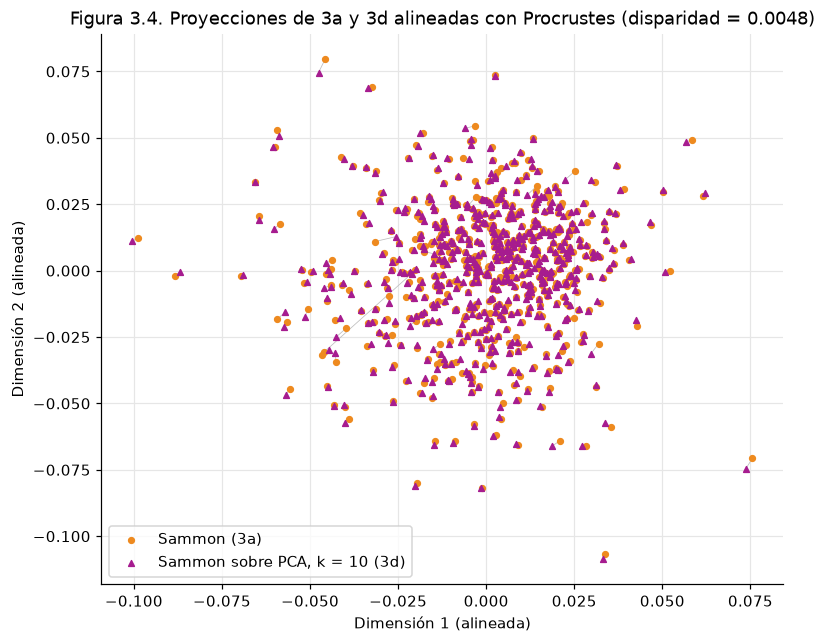

In [28]:
# ===========================================================
# Autor:       Ricardo
# Fecha:       04 noviembre 2026
# Descripción: Gráfica de las proyecciones de los incisos 3a y 3d alineadas con Procrustes.
# Insumo:      Z_sammon, Z_sammon_pca, disparidad_3a_3d.
# Resultado:   Figura 3.4 (figuras/figura_3.4_procrustes.png).
# ===========================================================
# procrustes regresa las dos proyecciones ya alineadas (centradas, a la misma escala y giradas);
# el tercer valor es la disparidad, que ya se calculó arriba, así que se descarta con "_"
alineada_3a, alineada_3d, _ = procrustes(Z_sammon, Z_sammon_pca)

fig, ax = plt.subplots(figsize=(8, 6.5))  # Figura de 8 x 6.5 pulgadas con un solo panel

# Una línea gris une cada observación en 3a con la misma observación en 3d;
# mientras más cortas sean las líneas, más parecidas son las proyecciones
for i in range(len(alineada_3a)):  # Recorre las 569 observaciones
    ax.plot([alineada_3a[i, 0], alineada_3d[i, 0]], [alineada_3a[i, 1], alineada_3d[i, 1]],
            color="#BDBDBD", linewidth=0.5, zorder=1)  # zorder=1: las líneas van detrás de los puntos

# Puntos de cada proyección con el color fijo de su método.
# marker="^" usa triángulos, para distinguirlas también sin color
ax.scatter(alineada_3a[:, 0], alineada_3a[:, 1], s=14, color=COLORES_METODO["Sammon"],
           label="Sammon (3a)", zorder=2)
ax.scatter(alineada_3d[:, 0], alineada_3d[:, 1], s=14, marker="^", color=COLORES_METODO["Sammon sobre PCA"],
           label=f"Sammon sobre PCA, k = {k95} (3d)", zorder=3)

ax.set_xlabel("Dimensión 1 (alineada)")
ax.set_ylabel("Dimensión 2 (alineada)")
ax.set_title(f"Figura 3.4. Proyecciones de 3a y 3d alineadas con Procrustes (disparidad = {disparidad_3a_3d:.4f})")
ax.legend()
fig.savefig(RUTA_FIGURAS / "figura_3.4_procrustes.png")  # Guarda la imagen para el reporte
plt.show()

### Métricas de Sammon para la tabla comparativa (inciso 5a)
Se calculan con las funciones compartidas de la Sección 0: stress de Sammon respecto a `X_std` (30 dimensiones) y exactitud de k-NN. Para Sammon sobre PCA, el tiempo es el de PCA más el de Sammon.

In [29]:
# ===========================================================
# Autor:       Ricardo
# Fecha:       04 noviembre 2026
# Descripción: Métricas de Sammon y Sammon sobre PCA para la tabla 5a.
# Insumo:      X_std, y, Z_sammon, Z_sammon_pca, t_sammon_directo, t_pca_k95, t_sammon_pca.
# Resultado:   Tabla 3.5 y filas Sammon y Sammon sobre PCA de comparativa.
# ===========================================================
# Stress de Sammon respecto a X_std y exactitud de k-NN de cada proyección
stress_sammon_3a = stress_sammon(X_std, Z_sammon)
stress_sammon_3d = stress_sammon(X_std, Z_sammon_pca)
knn_media_sammon, knn_std_sammon = evaluar_knn(Z_sammon, y)
knn_media_sammon_pca, knn_std_sammon_pca = evaluar_knn(Z_sammon_pca, y)
t_total_sammon_pca = t_pca_k95 + t_sammon_pca  # Tiempo de 3c + 3d

# --- REGISTRO EN LA TABLA COMPARATIVA ---
comparativa.loc["Sammon", "tiempo_s"] = round(t_sammon_directo, 4)
comparativa.loc["Sammon", "stress_sammon"] = round(stress_sammon_3a, 4)
comparativa.loc["Sammon", "knn_exactitud_media"] = round(knn_media_sammon, 4)
comparativa.loc["Sammon", "knn_exactitud_std"] = round(knn_std_sammon, 4)
comparativa.loc["Sammon", "notas"] = "Sammon sobre X_std; stress contra X_std (30D)"

comparativa.loc["Sammon sobre PCA", "tiempo_s"] = round(t_total_sammon_pca, 4)
comparativa.loc["Sammon sobre PCA", "stress_sammon"] = round(stress_sammon_3d, 4)
comparativa.loc["Sammon sobre PCA", "knn_exactitud_media"] = round(knn_media_sammon_pca, 4)
comparativa.loc["Sammon sobre PCA", "knn_exactitud_std"] = round(knn_std_sammon_pca, 4)
comparativa.loc["Sammon sobre PCA", "notas"] = f"PCA a k = {k95} + Sammon; tiempo = PCA + Sammon; stress contra X_std (30D)"

metricas_sammon = pd.DataFrame({
    "Métrica": ["Tiempo de transformación (s)", "Stress de Sammon (contra X_std)",
                "Exactitud k-NN (media)", "Exactitud k-NN (desviación)"],
    "Sammon": [t_sammon_directo, stress_sammon_3a, knn_media_sammon, knn_std_sammon],
    "Sammon sobre PCA": [t_total_sammon_pca, stress_sammon_3d, knn_media_sammon_pca, knn_std_sammon_pca],
})  # Cierra la creación de la tabla
print("Tabla 3.5. Métricas de Sammon y Sammon sobre PCA a 3 dimensiones")
display(metricas_sammon.round(4))

Tabla 3.5. Métricas de Sammon y Sammon sobre PCA a 3 dimensiones


,Métrica,Sammon,Sammon sobre PCA
0,Tiempo de transformación (s),1.2606,1.3076
1,Stress de Sammon (contra X_std),0.0175,0.0185
2,Exactitud k-NN (media),0.9367,0.9350
3,Exactitud k-NN (desviación),0.0128,0.0106


### Incisos 3g a 3i. Barrido de k
**Responsable:** Melanie

**Propósito:** medir cómo cambian el stress, la exactitud de k-NN y el tiempo según el número `k` de componentes de PCA que recibe Sammon.

**Insumo:** `X_std`, `y`, `pca_mas_sammon` y los resultados de los incisos 3a y 3d. **Resultado:** `barrido_k`, Tablas 3.6 a 3.8, Figuras 3.5 y 3.6 y `resultados/sammon_vs_k.csv`.

En esta parte, `k` es el número de dimensiones de PCA; el k-NN usa siempre 5 vecinos. Cada corrida usa la misma función, los mismos parámetros y la misma semilla que los incisos 3a y 3d.

In [30]:
# ===========================================================
# Autor:       Melanie
# Fecha:       05 noviembre 2026
# Descripción: Incisos 3g y 3h: barrido de k con PCA + Sammon y exactitud de k-NN.
# Insumo:      X_std, y, pca_mas_sammon.
# Resultado:   barrido_k, proyecciones_k, Tabla 3.6 y resultados/sammon_vs_k.csv.
# ===========================================================
K_BARRIDO = [3, 5, 10, 20, 30]  # Valores de k (número de componentes de PCA) que pide el inciso 3g

filas = []            # Lista vacía; se le agrega una fila de resultados por cada k
proyecciones_k = {}   # Diccionario k: proyección 3D; lo usan las comprobaciones de la Tabla 3.8
for k in K_BARRIDO:  # Repite el bloque con k = 3, 5, 10, 20 y 30
    # Función de Ricardo (incisos 3c + 3d): PCA a k dimensiones y Sammon a 3D sobre el resultado.
    # Regresa un diccionario con los tiempos, las dos proyecciones (k dimensiones y 3D) y el stress.
    corrida = pca_mas_sammon(X_std, k)
    proyecciones_k[k] = corrida["Z"]
    media_a, desviacion_a = evaluar_knn(corrida["Z_pca"], y)  # Versión A: PCA a k dimensiones
    media_b, desviacion_b = evaluar_knn(corrida["Z"], y)      # Versión B: Sammon 3D desde k
    # append agrega al final de la lista un diccionario; cada clave será una columna
    filas.append({
        "k": k,                             # Número de componentes de esta corrida
        "t_pca_s": corrida["t_pca"],        # Tiempo de PCA (3c), en segundos
        "t_sammon_s": corrida["t_sammon"],  # Tiempo de Sammon (3d), en segundos
        "t_total_s": corrida["t_total"],    # Tiempo de 3c + 3d, en segundos
        # Stress medido contra los datos que recibió Sammon (PCA a k dimensiones)
        "stress_libreria": corrida["stress_libreria"],
        # Stress medido contra X_std (30 dimensiones); este sí se compara entre valores de k
        "stress_contra_xstd": corrida["stress_xstd"],
        "knn_pca_k_media": media_a,         # Exactitud promedio, versión A
        "knn_pca_k_std": desviacion_a,      # Variación de la exactitud, versión A
        "knn_sammon_3d_media": media_b,     # Exactitud promedio, versión B
        "knn_sammon_3d_std": desviacion_b,  # Variación de la exactitud, versión B
    })  # Cierra el diccionario y la llamada a append

barrido_k = pd.DataFrame(filas)  # Convierte la lista de diccionarios en una tabla
exportar_csv(barrido_k, "sammon_vs_k.csv")  # CSV para las gráficas contra k del tablero
print("Tabla 3.6. Barrido de k: tiempos, stress final y exactitud de k-NN (incisos 3g y 3h)")
display(barrido_k.round(4))  # Muestra la tabla con 4 decimales

Aviso: se alcanzó maxiter; Sammon puede no haber convergido.


Tabla 3.6. Barrido de k: tiempos, stress final y exactitud de k-NN (incisos 3g y 3h)


,k,t_pca_s,t_sammon_s,t_total_s,stress_libreria,stress_contra_xstd,knn_pca_k_media,knn_pca_k_std,knn_sammon_3d_media,knn_sammon_3d_std
0,3,0.0005,1.5106,1.5111,0.0000,0.0593,0.9332,0.0226,0.9332,0.0226
1,5,0.0003,1.1482,1.1485,0.0045,0.0278,0.9526,0.0089,0.9350,0.0106
2,10,0.0003,1.3422,1.3425,0.0076,0.0185,0.9596,0.0105,0.9350,0.0106
3,20,0.0003,1.2223,1.2226,0.0093,0.0189,0.9666,0.0140,0.9508,0.0180
4,30,0.0003,1.4361,1.4364,0.0087,0.0175,0.9666,0.0140,0.9367,0.0128


### 3g. Stress final contra k
Se repiten los incisos 3c y 3d para cada `k` y se grafica el stress final. Se reportan dos valores:
- **Stress de la librería:** el que regresa Sammon, medido contra los datos que recibió (PCA a `k` dimensiones). Su referencia cambia con cada `k`. Además, la librería lo normaliza con un factor de 0.5, así que da la mitad del valor de la fórmula de `stress_sammon` (en el inciso 3a, cuya entrada es `X_std`, es exactamente la mitad del stress contra `X_std`).
- **Stress contra `X_std`:** medido contra los datos estandarizados de 30 dimensiones con `stress_sammon`. Como la referencia es la misma para todos los `k`, este es el que permite compararlos, y es el que va en la tabla 5a.

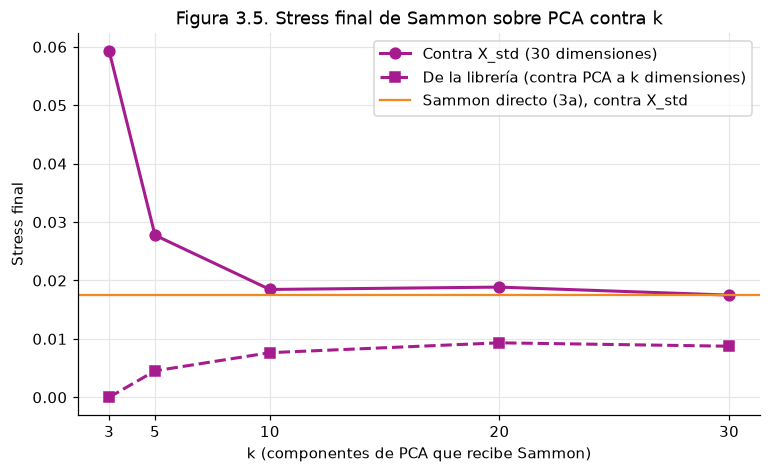

In [31]:
# ===========================================================
# Autor:       Melanie
# Fecha:       05 noviembre 2026
# Descripción: Inciso 3g: gráfica del stress final contra k.
# Insumo:      barrido_k, stress_sammon_3a.
# Resultado:   Figura 3.5 (figuras/figura_3.5_stress_contra_k.png).
# ===========================================================
color = COLORES_METODO["Sammon sobre PCA"]  # Las dos curvas son del mismo método, así que comparten color
fig, ax = plt.subplots(figsize=(8, 4.5))    # Figura con un solo panel
# Línea continua con círculos: stress contra X_std. marker es la forma del punto y label va en la leyenda
ax.plot(barrido_k["k"], barrido_k["stress_contra_xstd"], marker="o", markersize=7, linewidth=2,
        color=color, label="Contra X_std (30 dimensiones)")
# Línea punteada (linestyle="--") con cuadros: stress de la librería
ax.plot(barrido_k["k"], barrido_k["stress_libreria"], marker="s", markersize=7, linewidth=2,
        linestyle="--", color=color, label="De la librería (contra PCA a k dimensiones)")
# axhline dibuja una línea horizontal: el stress de Sammon directo (3a) sirve de referencia
ax.axhline(stress_sammon_3a, color=COLORES_METODO["Sammon"], linewidth=1.5,
           label="Sammon directo (3a), contra X_std")
ax.set_xticks(K_BARRIDO)  # Marca en el eje x solo los valores de k que se usaron
ax.set_xlabel("k (componentes de PCA que recibe Sammon)")
ax.set_ylabel("Stress final")
ax.set_title("Figura 3.5. Stress final de Sammon sobre PCA contra k")
ax.legend()
fig.savefig(RUTA_FIGURAS / "figura_3.5_stress_contra_k.png")  # Guarda la imagen para el reporte
plt.show()

### 3h. Exactitud de k-NN contra k
Se mide la exactitud de k-NN con `evaluar_knn` para cada `k`. El enunciado admite dos lecturas y el profesor todavía no lo aclara, así que se reportan las dos:
- **Versión A:** k-NN sobre los datos de PCA a `k` dimensiones (la lectura literal del inciso).
- **Versión B:** k-NN sobre la proyección de Sammon a 3D obtenida desde cada `k`.

Las barras de error son la desviación estándar entre las 5 particiones.

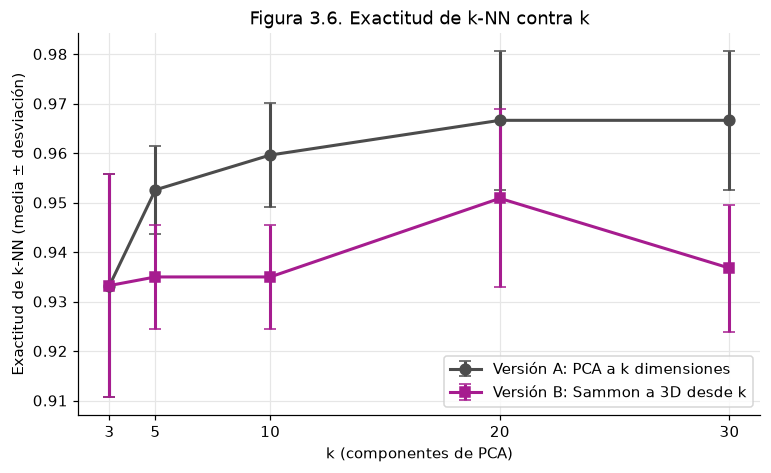

In [32]:
# ===========================================================
# Autor:       Melanie
# Fecha:       05 noviembre 2026
# Descripción: Inciso 3h: gráfica de la exactitud de k-NN contra k, en sus dos versiones.
# Insumo:      barrido_k.
# Resultado:   Figura 3.6 (figuras/figura_3.6_knn_contra_k.png).
# ===========================================================
fig, ax = plt.subplots(figsize=(8, 4.5))  # Figura con un solo panel
# errorbar dibuja una línea con barras de error: yerr es el largo de cada barra (la desviación).
# capsize es el ancho de la marca al final de cada barra.
ax.errorbar(barrido_k["k"], barrido_k["knn_pca_k_media"], yerr=barrido_k["knn_pca_k_std"],
            marker="o", markersize=7, linewidth=2, capsize=4, color=COLORES_METODO["PCA"],
            label="Versión A: PCA a k dimensiones")
# Versión B, con cuadros y el color de Sammon sobre PCA
ax.errorbar(barrido_k["k"], barrido_k["knn_sammon_3d_media"], yerr=barrido_k["knn_sammon_3d_std"],
            marker="s", markersize=7, linewidth=2, capsize=4, color=COLORES_METODO["Sammon sobre PCA"],
            label="Versión B: Sammon a 3D desde k")
ax.set_xticks(K_BARRIDO)  # Marca en el eje x solo los valores de k que se usaron
ax.set_xlabel("k (componentes de PCA)")
ax.set_ylabel("Exactitud de k-NN (media ± desviación)")
ax.set_title("Figura 3.6. Exactitud de k-NN contra k")
ax.legend()
fig.savefig(RUTA_FIGURAS / "figura_3.6_knn_contra_k.png")  # Guarda la imagen para el reporte
plt.show()

### 3i. Tabla de tiempos, stress y exactitud de k-NN
Se reúnen el tiempo total del inciso 3a (Sammon directo) y de los incisos 3c + 3d para cada `k`, junto con el stress final y la exactitud de k-NN. Sammon directo no pasa por PCA, así que no tiene `k`, tiempo de PCA ni versión A del k-NN.

In [33]:
# ===========================================================
# Autor:       Melanie
# Fecha:       05 noviembre 2026
# Descripción: Inciso 3i: tabla de tiempos, stress final y exactitud de k-NN.
# Insumo:      barrido_k, t_sammon_directo, stress_libreria_directo, stress_sammon_3a,
#              knn_media_sammon, knn_std_sammon (inciso 3a y métricas de Ricardo).
# Resultado:   tabla_3i y Tabla 3.7.
# ===========================================================
# Fila de Sammon directo (3a); reutiliza las métricas que ya calculó Ricardo para la tabla 5a
fila_directo = {
    "k": "Sammon directo (3a)",                # Sammon directo no usa PCA, así que no tiene k
    "t_sammon_s": t_sammon_directo,            # Tiempo total del inciso 3a
    "t_total_s": t_sammon_directo,
    "stress_libreria": stress_libreria_directo,
    "stress_contra_xstd": stress_sammon_3a,    # Misma referencia que la librería (X_std), pero la librería da la mitad: normaliza con 0.5
    "knn_sammon_3d_media": knn_media_sammon,
    "knn_sammon_3d_std": knn_std_sammon,
}  # Cierra el diccionario de la fila
# concat pega tablas una debajo de otra; astype permite mezclar texto y números en la columna k.
# ignore_index=True renumera las filas desde 0.
tabla_3i = pd.concat([pd.DataFrame([fila_directo]), barrido_k.astype({"k": object})], ignore_index=True)
# Ordena las columnas igual que el barrido, redondea y escribe "no aplica" en las celdas vacías
tabla_3i = tabla_3i[barrido_k.columns].round(4).astype(object).fillna("no aplica")
print("Tabla 3.7. Tiempo total, stress final y exactitud de k-NN: Sammon directo y Sammon sobre PCA (inciso 3i)")
display(tabla_3i)

Tabla 3.7. Tiempo total, stress final y exactitud de k-NN: Sammon directo y Sammon sobre PCA (inciso 3i)


,k,t_pca_s,t_sammon_s,t_total_s,stress_libreria,stress_contra_xstd,knn_pca_k_media,knn_pca_k_std,knn_sammon_3d_media,knn_sammon_3d_std
0,Sammon directo (3a),no aplica,1.2606,1.2606,0.0087,0.0175,no aplica,no aplica,0.9367,0.0128
1,3,0.0005,1.5106,1.5111,0.0,0.0593,0.9332,0.0226,0.9332,0.0226
2,5,0.0003,1.1482,1.1485,0.0045,0.0278,0.9526,0.0089,0.935,0.0106
3,10,0.0003,1.3422,1.3425,0.0076,0.0185,0.9596,0.0105,0.935,0.0106
4,20,0.0003,1.2223,1.2226,0.0093,0.0189,0.9666,0.014,0.9508,0.018
5,30,0.0003,1.4361,1.4364,0.0087,0.0175,0.9666,0.014,0.9367,0.0128


### Comprobaciones del barrido
Tres casos tienen un resultado esperado y sirven para revisar que el barrido sea consistente con los incisos 3a y 3d:
- **k = `k95`:** es la misma corrida del inciso 3d (misma entrada, función y semilla), así que la proyección debe ser idéntica.
- **k = 30:** con todas las componentes, PCA solo rota los datos y no cambia las distancias, así que en teoría el resultado debería coincidir con Sammon directo. En la práctica, la rotación introduce diferencias de redondeo mínimas y Sammon, que es muy sensible a su entrada, puede terminar en otra configuración (otro mínimo local). Por eso se comparan dos cosas: la disparidad de Procrustes, que mide si la forma es la misma, y el stress contra `X_std`, que mide si la calidad es la misma.
- **k = 3:** los datos de PCA ya están en 3D, así que el stress de la librería debe acercarse a 0. Eso no significa que la proyección sea mejor: contra `X_std` el stress sigue siendo el de una proyección a 3D.

In [34]:
# ===========================================================
# Autor:       Melanie
# Fecha:       05 noviembre 2026
# Descripción: Comprobaciones del barrido contra los incisos 3a y 3d.
# Insumo:      proyecciones_k, barrido_k, Z_sammon, Z_sammon_pca, k95, stress_sammon_3a.
# Resultado:   Tabla 3.8.
# ===========================================================
# set_index("k") permite buscar la fila de cada k con loc[k, columna]
por_k = barrido_k.set_index("k")

# k = k95: allclose da True si las dos proyecciones son iguales salvo errores de redondeo
igual_3d = np.allclose(proyecciones_k[k95], Z_sammon_pca)
# k = 30: procrustes alinea las dos proyecciones; el tercer valor es la disparidad (0 = idénticas)
_, _, disparidad_k30 = procrustes(Z_sammon, proyecciones_k[30])
# Diferencia relativa del stress contra X_std: abs() es el valor absoluto
dif_stress_k30 = abs(por_k.loc[30, "stress_contra_xstd"] - stress_sammon_3a) / stress_sammon_3a
stress_k3_lib = por_k.loc[3, "stress_libreria"]

comprobaciones = pd.DataFrame(
    [
        (f"k = {k95} (k95) contra 3d", "¿Proyección idéntica a la del inciso 3d?",
         "Sí" if igual_3d else "No",
         "Coincide: misma entrada, función y semilla" if igual_3d else "No coincide: revisar parámetros"),
        ("k = 30 contra 3a", "Diferencia relativa del stress contra X_std",
         f"{dif_stress_k30:.1%}",  # :.1% lo escribe como porcentaje con 1 decimal
         "Calidad prácticamente igual" if dif_stress_k30 < 0.05 else "La calidad cambia"),
        ("k = 30 contra 3a", "Disparidad de Procrustes",
         f"{disparidad_k30:.4f}",
         "Prácticamente idénticas" if disparidad_k30 < 1e-4
         else "No es 0: el redondeo de la rotación llevó a Sammon a otra configuración"),
        ("k = 3", "Stress de la librería / stress contra X_std",
         f"{stress_k3_lib:.2e} / {por_k.loc[3, 'stress_contra_xstd']:.4f}",
         "≈ 0 contra su entrada; el que se compara es el de X_std"),
    ],
    columns=["Caso", "Qué se compara", "Valor", "Lectura"],
)  # Cierra la creación de la tabla
print("Tabla 3.8. Comprobaciones del barrido de k contra los incisos 3a y 3d")
display(comprobaciones)

Tabla 3.8. Comprobaciones del barrido de k contra los incisos 3a y 3d


,Caso,Qué se compara,Valor,Lectura
0,k = 10 (k95) contra 3d,¿Proyección idéntica a la del inciso 3d?,Sí,"Coincide: misma entrada, función y semilla"
1,k = 30 contra 3a,Diferencia relativa del stress contra X_std,0.0%,Calidad prácticamente igual
2,k = 30 contra 3a,Disparidad de Procrustes,0.0000,Prácticamente idénticas
3,k = 3,Stress de la librería / stress contra X_std,1.95e-20 / 0.0593,≈ 0 contra su entrada; el que se compara es el...


## Sección 4. Autocodificador
**Responsable:** Santiago

**Propósito:** proyectar los datos originales a 3 dimensiones con un autocodificador no lineal, medir el tiempo de entrenamiento y el de proyección, y graficar el espacio latente.

**Insumo:** `X`, `X_std`, `y`, `scaler`. **Resultado:** `codificador`, `Z_ae`, Tablas 4.1 a 4.3, Figuras 4.1 y 4.2, `resultados/autoencoder_perdida.csv` y `resultados/autoencoder_3d.csv`.

Un autocodificador es una red neuronal que aprende a reconstruir sus propios datos de entrada. Tiene dos partes: el **codificador** comprime las 30 variables en una capa de solo 3 neuronas y el **decodificador** intenta recuperar las 30 variables a partir de esos 3 valores. Esa capa de en medio es el **cuello de botella**, también llamado **espacio latente**. Si la reconstrucción sale bien, esos 3 valores guardan lo importante de cada observación, así que sirven como proyección a 3D.

### 4a. Datos de entrenamiento y validación
El inciso pide transformar los **datos originales** (en los incisos 2a y 3a se usaron los estandarizados), así que la red recibe `X` tal cual. El 20% de las filas se aparta para validación, que sirve para saber cuándo dejar de entrenar. Para separarlas se usa `train_test_split` estratificado y no el `validation_split` de Keras, porque ese toma las últimas filas sin revolverlas y, en este conjunto, los tumores malignos se concentran al principio.

In [35]:
# ===========================================================
# Autor:       Santiago
# Fecha:       06 noviembre 2026
# Descripción: Librerías de la Sección 4 y separación de los datos en entrenamiento y validación.
# Insumo:      X, X_std, y, SEED.
# Resultado:   X_ent, X_val, X_std_ent, X_std_val.
# ===========================================================
import tensorflow as tf                               # Librería de redes neuronales; tf.keras es la parte para armarlas por capas
from sklearn.model_selection import train_test_split  # Separa las filas en un conjunto de entrenamiento y otro de validación

# train_test_split revuelve las filas y parte al mismo tiempo X (datos originales, la entrada de la red) y X_std
# (lo que la red debe reconstruir), para que las dos queden con las mismas filas; por eso regresa cuatro partes:
# entrenamiento y validación de X, y entrenamiento y validación de X_std. test_size=0.2 manda el 20% a validación,
# stratify=y conserva la misma proporción de malignos y benignos en los dos conjuntos
# y random_state hace que el reparto sea siempre el mismo.
X_ent, X_val, X_std_ent, X_std_val = train_test_split(X, X_std, test_size=0.2, stratify=y, random_state=SEED)
print(f"Entrenamiento: {len(X_ent)} filas | Validación: {len(X_val)} filas")  # len da el número de filas

Entrenamiento: 455 filas | Validación: 114 filas


### Arquitectura
La arquitectura es 30 → 16 → 8 → **3** → 8 → 16 → 30: el codificador reduce las variables poco a poco, más o menos a la mitad en cada capa, hasta llegar a 3, y el decodificador hace el mismo camino de regreso. Es una red pequeña (1,345 parámetros, Tabla 4.1), porque con 569 observaciones una red grande se sobreajusta con facilidad. Cada capa densa calcula $h = \sigma(Wx + b)$, donde $W$ son los pesos, $b$ el sesgo y $\sigma$ la función de activación (notas de clase).

- **Primera capa (`Normalization`):** las variables tienen escalas muy distintas (Sección 1), por eso la red las estandariza al entrar con la media y la varianza del `scaler` de la Sección 0. De esta forma la red recibe los datos originales y su salida se puede comparar con `X_std`.
- **Capas ocultas con activación ELU:** la activación es lo que hace no lineal al autocodificador. ELU deja igual los valores positivos y a los negativos los convierte en $e^x - 1$, un valor entre −1 y 0, así que ninguna neurona se queda atorada en cero, como puede pasar con ReLU.
- **Capa latente (3 neuronas) y capa de salida (30 neuronas) sin activación,** para que puedan dar cualquier valor, positivo o negativo.

In [36]:
# ===========================================================
# Autor:       Santiago
# Fecha:       06 noviembre 2026
# Descripción: Construcción del autocodificador (codificador + decodificador).
# Insumo:      scaler, SEED.
# Resultado:   codificador, decodificador, autocodificador y Tabla 4.1.
# ===========================================================
# Fija las semillas de Python, NumPy y TensorFlow (README, sección 3.2); de ellas dependen los pesos
# iniciales de la red y el orden en que se barajan los datos al entrenar
tf.keras.utils.set_random_seed(SEED)

# Sequential arma un modelo con capas que se aplican una tras otra, en el orden de la lista
codificador = tf.keras.Sequential([
    tf.keras.Input(shape=(30,)),                    # Cada observación entra como un vector de 30 valores originales
    # Estandariza cada variable, (x - media) / raíz de la varianza, con los valores del StandardScaler de la Sección 0.
    # Como se le pasan ya calculados, Keras los guarda como constantes y no como pesos: no se entrenan
    # ni cuentan como parámetros, por eso esta capa tiene 0 en la Tabla 4.1
    tf.keras.layers.Normalization(mean=scaler.mean_, variance=scaler.var_),
    # Capa densa de 16 neuronas: cada neurona recibe las 30 entradas y la capa calcula h = elu(Wx + b),
    # con 30 × 16 pesos (W) y 16 sesgos (b), que son los 496 parámetros de la Tabla 4.1
    tf.keras.layers.Dense(16, activation="elu"),
    tf.keras.layers.Dense(8, activation="elu"),     # Capa densa de 8 neuronas con ELU
    tf.keras.layers.Dense(3),                       # Espacio latente: 3 neuronas sin activación
], name="codificador")                              # Cierra la lista de capas y nombra el modelo

# El decodificador hace el camino inverso: de los 3 valores del espacio latente regresa a las 30 variables
decodificador = tf.keras.Sequential([
    tf.keras.Input(shape=(3,)),                     # Recibe un punto del espacio latente
    tf.keras.layers.Dense(8, activation="elu"),     # Capa densa de 8 neuronas con ELU
    tf.keras.layers.Dense(16, activation="elu"),    # Capa densa de 16 neuronas con ELU
    tf.keras.layers.Dense(30),                      # Salida: las 30 variables estandarizadas, sin activación
], name="decodificador")

# El autocodificador es el codificador seguido del decodificador. Como usa esas mismas capas,
# al entrenarlo quedan entrenados los dos
autocodificador = tf.keras.Sequential([codificador, decodificador], name="autocodificador")
# compile define cómo se va a entrenar: el optimizador Adam ajusta los pesos para minimizar el error
# cuadrático medio (loss="mse"); se usa su tasa de aprendizaje por defecto, 0.001
autocodificador.compile(optimizer="adam", loss="mse")

print("Tabla 4.1. Arquitectura del autocodificador")
# summary muestra cada capa, la forma de su salida (None es el número de filas, que no está fijo) y su número
# de parámetros (pesos + sesgos); expand_nested=True muestra también las capas de dentro del codificador
# y del decodificador
autocodificador.summary(expand_nested=True)

Tabla 4.1. Arquitectura del autocodificador


Model: "autocodificador"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ codificador (Sequential)        │ (None, 3)              │           659 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ normalization              │ (None, 30)             │             0 │
│ (Normalization)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ dense (Dense)              │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ dense_1 (Dense)            │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ dense_2 (Dense)            │ (None, 3)              │            27 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decodificador (Sequential)      │ (None, 30)             │           686 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ dense_3 (Dense)            │ (None, 8)              │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ dense_4 (Dense)            │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ dense_5 (Dense)            │ (None, 30)             │           510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,345 (5.25 KB)

 Trainable params: 1,345 (5.25 KB)

 Non-trainable params: 0 (0.00 B)

### Entrenamiento y tiempo de entrenamiento (inciso 4a, i)
La red se entrena para que su salida se parezca lo más posible a `X_std`. La pérdida es el error cuadrático medio entre cada fila de `X_std` ($x$) y la salida de la red ($\hat{x}$), $\mathcal{L}(x, \hat{x}) = \frac{1}{n}\sum_{i=1}^{n}(x_i - \hat{x}_i)^2$ con $n = 30$ variables, y el optimizador es Adam.

Para no sobreajustar, al final de cada época se mide la pérdida en los datos de validación: si no mejora en 50 épocas seguidas, el entrenamiento se detiene y se recuperan los pesos de la mejor época (`EarlyStopping`). No se usa Dropout, porque el cuello de botella de 3 neuronas ya impide que la red solo copie los datos. Se mide solo el tiempo de `fit`, que es el entrenamiento.

In [37]:
# ===========================================================
# Autor:       Santiago
# Fecha:       06 noviembre 2026
# Descripción: Entrenamiento del autocodificador y medición del tiempo de entrenamiento (inciso 4a, i).
# Insumo:      autocodificador, X_ent, X_std_ent, X_val, X_std_val.
# Resultado:   historial, t_entrenamiento_ae, mejor_epoca.
# ===========================================================
# Parada temprana: vigila la pérdida de validación (val_loss), detiene el entrenamiento si no mejora
# en 50 épocas seguidas (patience) y al final deja los pesos de la mejor época (restore_best_weights)
parada_temprana = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=50, restore_best_weights=True)

# --- MEDICIÓN DEL TIEMPO DE ENTRENAMIENTO ---
t0 = perf_counter()  # Inicio del cronómetro
# fit entrena la red: la entrada son los datos originales (X_ent) y el objetivo son esas mismas filas
# estandarizadas (X_std_ent). En cada época (una pasada por todas las filas de entrenamiento) baraja las filas
# y las recorre en lotes de 32 (batch_size); por cada lote calcula la salida, la pérdida y los gradientes
# (retropropagación), y Adam actualiza los pesos. Al terminar cada época mide la pérdida en validation_data,
# sin entrenar con esas filas, y la parada temprana (callbacks) revisa ese valor.
# epochs=3000 es solo un tope, porque la parada temprana termina antes; verbose=0 no imprime el avance.
historial = autocodificador.fit(X_ent, X_std_ent, validation_data=(X_val, X_std_val),
                                epochs=3000, batch_size=32, callbacks=[parada_temprana], verbose=0)
t_entrenamiento_ae = perf_counter() - t0  # Tiempo de entrenamiento en segundos

# best_epoch es la época con menor pérdida de validación; se cuenta desde 0, por eso se suma 1
mejor_epoca = parada_temprana.best_epoch + 1
print(f"Tiempo de entrenamiento: {t_entrenamiento_ae:.4f} s")
# historial.history es un diccionario con la pérdida de cada época: 'loss' (entrenamiento) y 'val_loss' (validación);
# el largo de la lista 'loss' es el número de épocas entrenadas
print(f"Épocas entrenadas: {len(historial.history['loss'])} | Mejor época: {mejor_epoca}")

Tiempo de entrenamiento: 7.6273 s
Épocas entrenadas: 345 | Mejor época: 295


### Curva de pérdida
La línea vertical marca la mejor época, que es la que se queda en el modelo.

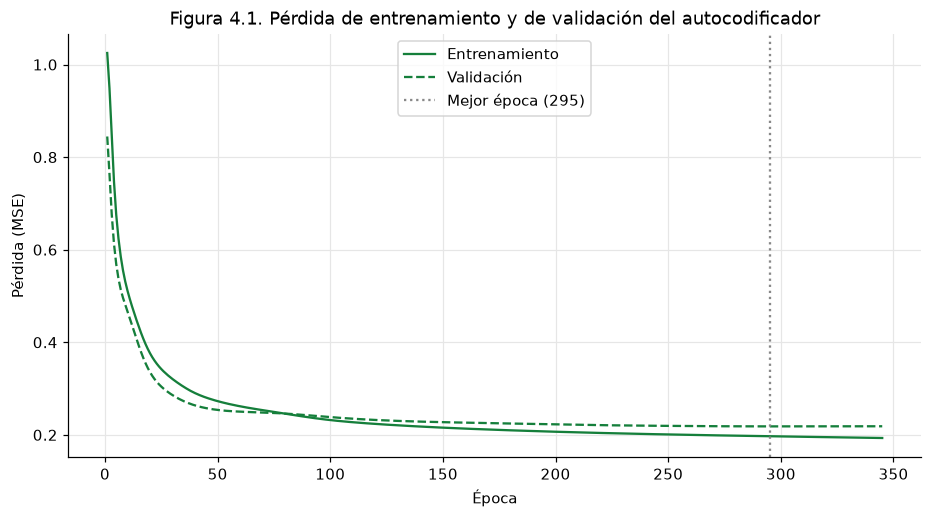

In [38]:
# ===========================================================
# Autor:       Santiago
# Fecha:       06 noviembre 2026
# Descripción: Curva de pérdida por época del autocodificador y su exportación.
# Insumo:      historial, mejor_epoca.
# Resultado:   Figura 4.1 (figuras/figura_4.1_perdida_autocodificador.png) y resultados/autoencoder_perdida.csv.
# ===========================================================
# Tabla con la pérdida de cada época; sirve para la gráfica y para el tablero
perdida = pd.DataFrame({
    "epoca": range(1, len(historial.history["loss"]) + 1),  # range da 1, 2, ..., número de épocas
    "perdida_entrenamiento": historial.history["loss"],     # Promedio del MSE de los lotes de cada época
    "perdida_validacion": historial.history["val_loss"],    # MSE de validación, medido al terminar cada época
})  # Cierra la creación de la tabla

color = COLORES_METODO["Autocodificador"]  # Verde, el color fijo del método
fig, ax = plt.subplots(figsize=(10, 5))    # Figura de 10 x 5 pulgadas con un solo panel
# Las dos curvas son del mismo método, así que llevan el mismo color: entrenamiento con línea continua
# y validación con línea discontinua (linestyle="--")
ax.plot(perdida["epoca"], perdida["perdida_entrenamiento"], color=color, label="Entrenamiento")
ax.plot(perdida["epoca"], perdida["perdida_validacion"], color=color, linestyle="--", label="Validación")
# axvline dibuja una línea vertical gris y punteada (linestyle=":") en la mejor época
ax.axvline(mejor_epoca, color="#888888", linestyle=":", label=f"Mejor época ({mejor_epoca})")
ax.set_xlabel("Época")
ax.set_ylabel("Pérdida (MSE)")
ax.set_title("Figura 4.1. Pérdida de entrenamiento y de validación del autocodificador")
ax.legend()
fig.savefig(RUTA_FIGURAS / "figura_4.1_perdida_autocodificador.png")  # Guarda la imagen para el reporte
plt.show()

exportar_csv(perdida, "autoencoder_perdida.csv")  # Para el tablero (README, sección 3.8)

### Proyección y tiempo de proyección (inciso 4a, ii)
Ya entrenado, el codificador transforma las 569 observaciones originales a 3 dimensiones. Se mide solo esa transformación.

In [39]:
# ===========================================================
# Autor:       Santiago
# Fecha:       06 noviembre 2026
# Descripción: Proyección de los datos originales con el codificador entrenado y medición del tiempo (inciso 4a, ii).
# Insumo:      codificador, X, y.
# Resultado:   Z_ae, t_proyeccion_ae, tabla_ae_3d y Tabla 4.2.
# ===========================================================
# --- MEDICIÓN DEL TIEMPO DE PROYECCIÓN ---
t0 = perf_counter()  # Inicio del cronómetro
# predict pasa las 569 observaciones originales por el codificador ya entrenado y regresa sus 3 coordenadas;
# solo calcula la salida, no cambia los pesos
Z_ae = codificador.predict(X, verbose=0)
t_proyeccion_ae = perf_counter() - t0  # Tiempo de proyección en segundos

print(f"Tiempo de proyección: {t_proyeccion_ae:.4f} s")
print(f"Dimensiones antes: {X.shape} -> después: {Z_ae.shape}")  # Mismas 569 filas, ahora con 3 columnas

# Tabla con las coordenadas en el espacio latente y la clase de cada observación
tabla_ae_3d = pd.DataFrame(Z_ae, columns=["z1", "z2", "z3"])
tabla_ae_3d["Clase"] = y.values  # values da las etiquetas sin índice
print("Tabla 4.2. Primeras 5 observaciones en el espacio latente del autocodificador")
display(tabla_ae_3d.head().round(4))

Tiempo de proyección: 0.0526 s
Dimensiones antes: (569, 30) -> después: (569, 3)
Tabla 4.2. Primeras 5 observaciones en el espacio latente del autocodificador


,z1,z2,z3,Clase
0,7.8884,0.9491,-5.3111,Maligno
1,2.7265,2.8983,-1.4319,Maligno
2,4.7588,1.4751,-3.6797,Maligno
3,6.1787,-2.8584,-1.0090,Maligno
4,3.5049,1.5832,-3.9341,Maligno


### Gráfica del espacio latente (inciso 4a)
La red nunca vio el diagnóstico. Si aun así las clases salen separadas, es porque esa diferencia ya estaba en las 30 variables.

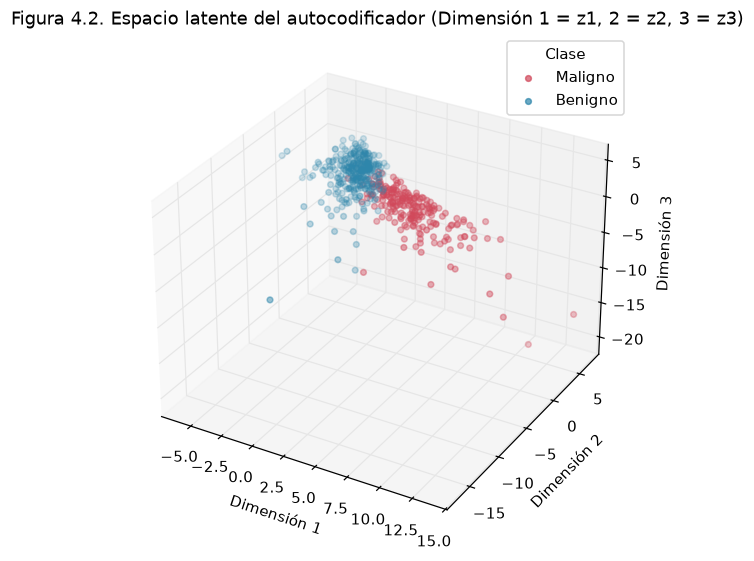

In [40]:
# ===========================================================
# Autor:       Santiago
# Fecha:       06 noviembre 2026
# Descripción: Dispersión 3D del espacio latente y su exportación.
# Insumo:      Z_ae, y, tabla_ae_3d.
# Resultado:   Figura 4.2 (figuras/figura_4.2.png) y resultados/autoencoder_3d.csv.
# ===========================================================
# graficar_3d es la función compartida de la Sección 0: usa COLORES_CLASE y guarda la imagen.
# Recibe la proyección, las clases, el título y el número de figura, que va en el título y en el nombre del archivo
graficar_3d(Z_ae, y, "Espacio latente del autocodificador (Dimensión 1 = z1, 2 = z2, 3 = z3)", "4.2")
exportar_csv(tabla_ae_3d, "autoencoder_3d.csv")  # Para el tablero (z1, z2, z3, Clase)

### Métricas del autocodificador para la tabla comparativa (inciso 5a)
Se calculan con las funciones de la Sección 0: error de reconstrucción (MSE en el espacio estandarizado, como el de PCA), stress de Sammon contra `X_std` y exactitud de k-NN. El tiempo del método es el de entrenamiento más el de proyección.

In [41]:
# ===========================================================
# Autor:       Santiago
# Fecha:       06 noviembre 2026
# Descripción: Métricas del autocodificador para la tabla 5a.
# Insumo:      autocodificador, X, X_std, Z_ae, y, t_entrenamiento_ae, t_proyeccion_ae.
# Resultado:   Tabla 4.3 y fila Autocodificador de comparativa.
# ===========================================================
X_rec_ae = autocodificador.predict(X, verbose=0)  # Reconstrucción: las 30 variables estandarizadas que da la red
mse_ae = error_reconstruccion(X_std, X_rec_ae)    # Error de reconstrucción (MSE) contra X_std
stress_ae = stress_sammon(X_std, Z_ae)            # Cuánto se deformaron las distancias al pasar de 30D a 3D
knn_media_ae, knn_std_ae = evaluar_knn(Z_ae, y)   # Exactitud de k-NN: media y desviación de las 5 particiones

# --- REGISTRO EN LA TABLA COMPARATIVA ---
# .loc[fila, columna] = valor; round(4) deja 4 decimales, como acordó el equipo.
# El tiempo total se suma antes de redondear, así que puede diferir en el último decimal de la suma de las dos columnas
comparativa.loc["Autocodificador", "tiempo_s"] = round(t_entrenamiento_ae + t_proyeccion_ae, 4)
comparativa.loc["Autocodificador", "tiempo_entrenamiento_s"] = round(t_entrenamiento_ae, 4)
comparativa.loc["Autocodificador", "tiempo_proyeccion_s"] = round(t_proyeccion_ae, 4)
comparativa.loc["Autocodificador", "stress_sammon"] = round(stress_ae, 4)
comparativa.loc["Autocodificador", "knn_exactitud_media"] = round(knn_media_ae, 4)
comparativa.loc["Autocodificador", "knn_exactitud_std"] = round(knn_std_ae, 4)
comparativa.loc["Autocodificador", "error_reconstruccion_mse"] = round(mse_ae, 4)
comparativa.loc["Autocodificador", "notas"] = "Entrada: datos originales; tiempo = entrenamiento + proyección; stress contra X_std (30D)"

# Tabla de evidencia con las métricas del autocodificador
metricas_ae = pd.DataFrame({
    "Métrica": ["Tiempo de entrenamiento (s)", "Tiempo de proyección (s)", "Stress de Sammon (contra X_std)",
                "Exactitud k-NN (media)", "Exactitud k-NN (desviación)", "Error de reconstrucción (MSE)"],
    "Valor": [t_entrenamiento_ae, t_proyeccion_ae, stress_ae, knn_media_ae, knn_std_ae, mse_ae],
})  # Cierra la creación de la tabla
print("Tabla 4.3. Métricas del autocodificador a 3 dimensiones")
display(metricas_ae.round(4))

Tabla 4.3. Métricas del autocodificador a 3 dimensiones


,Métrica,Valor
0,Tiempo de entrenamiento (s),7.6273
1,Tiempo de proyección (s),0.0526
2,Stress de Sammon (contra X_std),0.1374
3,Exactitud k-NN (media),0.9420
4,Exactitud k-NN (desviación),0.0180
5,Error de reconstrucción (MSE),0.2007


## Sección 5. Análisis y conclusiones
**Responsable:** Santiago

**Propósito:** reunir los resultados de los cuatro métodos en una sola tabla (inciso 5a) y compararlos para ver en qué se diferencian y qué patrones deja ver cada uno en 3D (inciso 5b).

**Insumo:** `comparativa`, con las filas que registraron las Secciones 2, 3 y 4. **Resultado:** Tablas 5.1 y 5.2 y `resultados/comparativa.csv`.

### 5a. Tabla única de resultados
Cada sección registró sus métricas con las mismas funciones de la Sección 0, así que se pueden comparar directamente. Sammon no reconstruye los datos, por eso su error de reconstrucción dice "no aplica".

In [42]:
# ===========================================================
# Autor:       Santiago
# Fecha:       06 noviembre 2026
# Descripción: Inciso 5a: tabla única con los resultados de los cuatro métodos y su exportación.
# Insumo:      comparativa.
# Resultado:   Tabla 5.1 y resultados/comparativa.csv.
# ===========================================================
# reset_index convierte el índice (el nombre del método) en una columna, para que se guarde en el CSV
exportar_csv(comparativa.reset_index(), "comparativa.csv")
print("Tabla 5.1. Resultados de PCA, Sammon, Sammon sobre PCA y el autocodificador (inciso 5a)")
# drop quita la columna de notas solo para mostrar la tabla (pandas cortaría esos textos); en el CSV quedan completas
display(comparativa.drop(columns="notas"))

Tabla 5.1. Resultados de PCA, Sammon, Sammon sobre PCA y el autocodificador (inciso 5a)


,tiempo_s,tiempo_entrenamiento_s,tiempo_proyeccion_s,stress_sammon,knn_exactitud_media,knn_exactitud_std,error_reconstruccion_mse
metodo,,,,,,,
PCA,0.0006,no aplica,no aplica,0.0593,0.9332,0.0226,0.2736
Sammon,1.2606,no aplica,no aplica,0.0175,0.9367,0.0128,no aplica
Sammon sobre PCA,1.3076,no aplica,no aplica,0.0185,0.935,0.0106,no aplica
Autocodificador,7.6799,7.6273,0.0526,0.1374,0.942,0.018,0.2007


### 5b. Análisis de los resultados

**Diferencias en la Tabla 5.1**

- **Tiempo:** PCA tarda menos de un milisegundo y Sammon alrededor de un segundo, porque en cada iteración recalcula las distancias entre todos los pares de puntos; aplicarlo sobre PCA no lo acelera. El autocodificador es el más lento (entre 7 y 8 segundos, casi todo de entrenamiento), pero ya entrenado proyecta en una fracción de segundo.
- **Stress:** Sammon es el que mejor conserva las distancias de `X_std` (0.0175), porque es justo lo que optimiza, y sobre PCA queda casi igual (0.0185). PCA tiene más del triple (0.0593) y el autocodificador es el que más deforma las distancias (0.1374): PCA solo rota los datos y quita ejes, mientras que la red puede estirar o encoger el espacio.
- **Exactitud de k-NN:** los cuatro quedan entre 0.933 y 0.942, una diferencia menor que su desviación estándar, así que separan las clases prácticamente igual de bien. Con todas las dimensiones llegaría a 0.967 (Tabla 3.6, k = 30): pasar a 3D cuesta unos 3 puntos porcentuales.
- **Error de reconstrucción:** el autocodificador tiene 27% menos error que PCA (0.2007 contra 0.2736). Como PCA ya es la mejor reconstrucción lineal posible con 3 componentes (conserva el 72.6% de la varianza, inciso 2b), esa mejora viene de que el autocodificador es no lineal.

**Patrones en 3D (Figuras 2.3, 3.2, 3.3 y 4.2)**

En las cuatro figuras se ve lo mismo: los tumores benignos forman un grupo compacto y los malignos una nube más dispersa que se aleja de él, con una zona donde las dos clases se enciman. Lo que cambia es lo que aporta cada método:

- **PCA:** sus ejes se pueden interpretar. Según la Tabla 2.3, PC1 crece con el tamaño y la concavidad del tumor, y la mayoría de los malignos quedan del lado positivo.
- **Sammon y Sammon sobre PCA:** dan casi la misma imagen (disparidad de Procrustes de 0.0048, inciso 3f) y son los que mejor respetan las distancias entre observaciones.
- **Autocodificador:** muestra el mismo patrón, con los malignos extendidos hacia un lado, pero sus ejes no tienen una interpretación directa.

Todo esto parte de estandarizar los datos (el autocodificador lo hace en su primera capa): sin eso, las variables de área y perímetro, que concentran casi toda la varianza original (inciso 1c), dominarían en los cuatro métodos.

**Tabla 5.2. Qué gana y qué pierde cada método**

| Método | Gana | Pierde |
|---|---|---|
| PCA | Es instantáneo, siempre da el mismo resultado y sus ejes se pueden interpretar | Deforma las distancias más que Sammon y solo capta relaciones lineales |
| Sammon | Es el que mejor conserva las distancias | Se vuelve lento con muchos datos y no puede proyectar datos nuevos |
| Sammon sobre PCA | Da casi lo mismo que Sammon, con menos variables de entrada | Aquí no ahorra tiempo |
| Autocodificador | Es el que mejor reconstruye los datos y, ya entrenado, proyecta datos nuevos muy rápido | Es el más lento de entrenar, depende de muchas decisiones de diseño, es el que más deforma las distancias y sus ejes no se interpretan |

**Conclusión**

Para visualizar este conjunto en 3D conviene **Sammon**: es el que mejor respeta las distancias entre observaciones, separa las clases igual que los demás y tarda alrededor de un segundo; hacerlo sobre PCA no cambia el resultado. PCA es la mejor opción si importa la rapidez o interpretar los ejes, y el autocodificador solo vale la pena si el objetivo es reconstruir los datos.

Los tiempos son de una sola corrida en la computadora de la Sección 0, y los resultados de Sammon y del autocodificador pueden cambiar un poco en otra computadora, aunque se use la misma semilla.

## Sección 6. Tablero de resultados
**Responsable:** Magaly

**Propósito:** presentar en una sola vista qué método de reducción de dimensiones conviene y por qué, a partir de los resultados de las Secciones 2 a 4.

**6a. Exportación de resultados.** Las Secciones 2 a 4 exportaron sus resultados a la carpeta `resultados/` con la función compartida `exportar_csv`, que escribe "no aplica" en lugar de cero cuando un valor no corresponde. Se generaron 11 archivos: `pca_varianza.csv`, `pca_error_reconstruccion.csv`, `pca_3d.csv`, `sammon_3d.csv`, `sammon_pca_3d.csv`, `sammon_stress_iteraciones.csv`, `sammon_procrustes.csv`, `sammon_vs_k.csv`, `autoencoder_3d.csv`, `autoencoder_perdida.csv` y `comparativa.csv`.

**6b y 6d. Tablero.** Se construyó en Power BI (`tablero/Tablero_Practica02.pbix`) y lee únicamente archivos de `resultados/`: `comparativa.csv` para los indicadores, las barras y la tabla, y los cuatro archivos de proyecciones 3D para las dispersiones. Ningún número se escribió a mano. La vista responde la pregunta "¿qué método conviene?" con esta jerarquía: la pregunta, tres indicadores de Sammon con su referencia, la evidencia (stress por método y proyecciones de los cuatro métodos), la tabla de métricas y la conclusión.

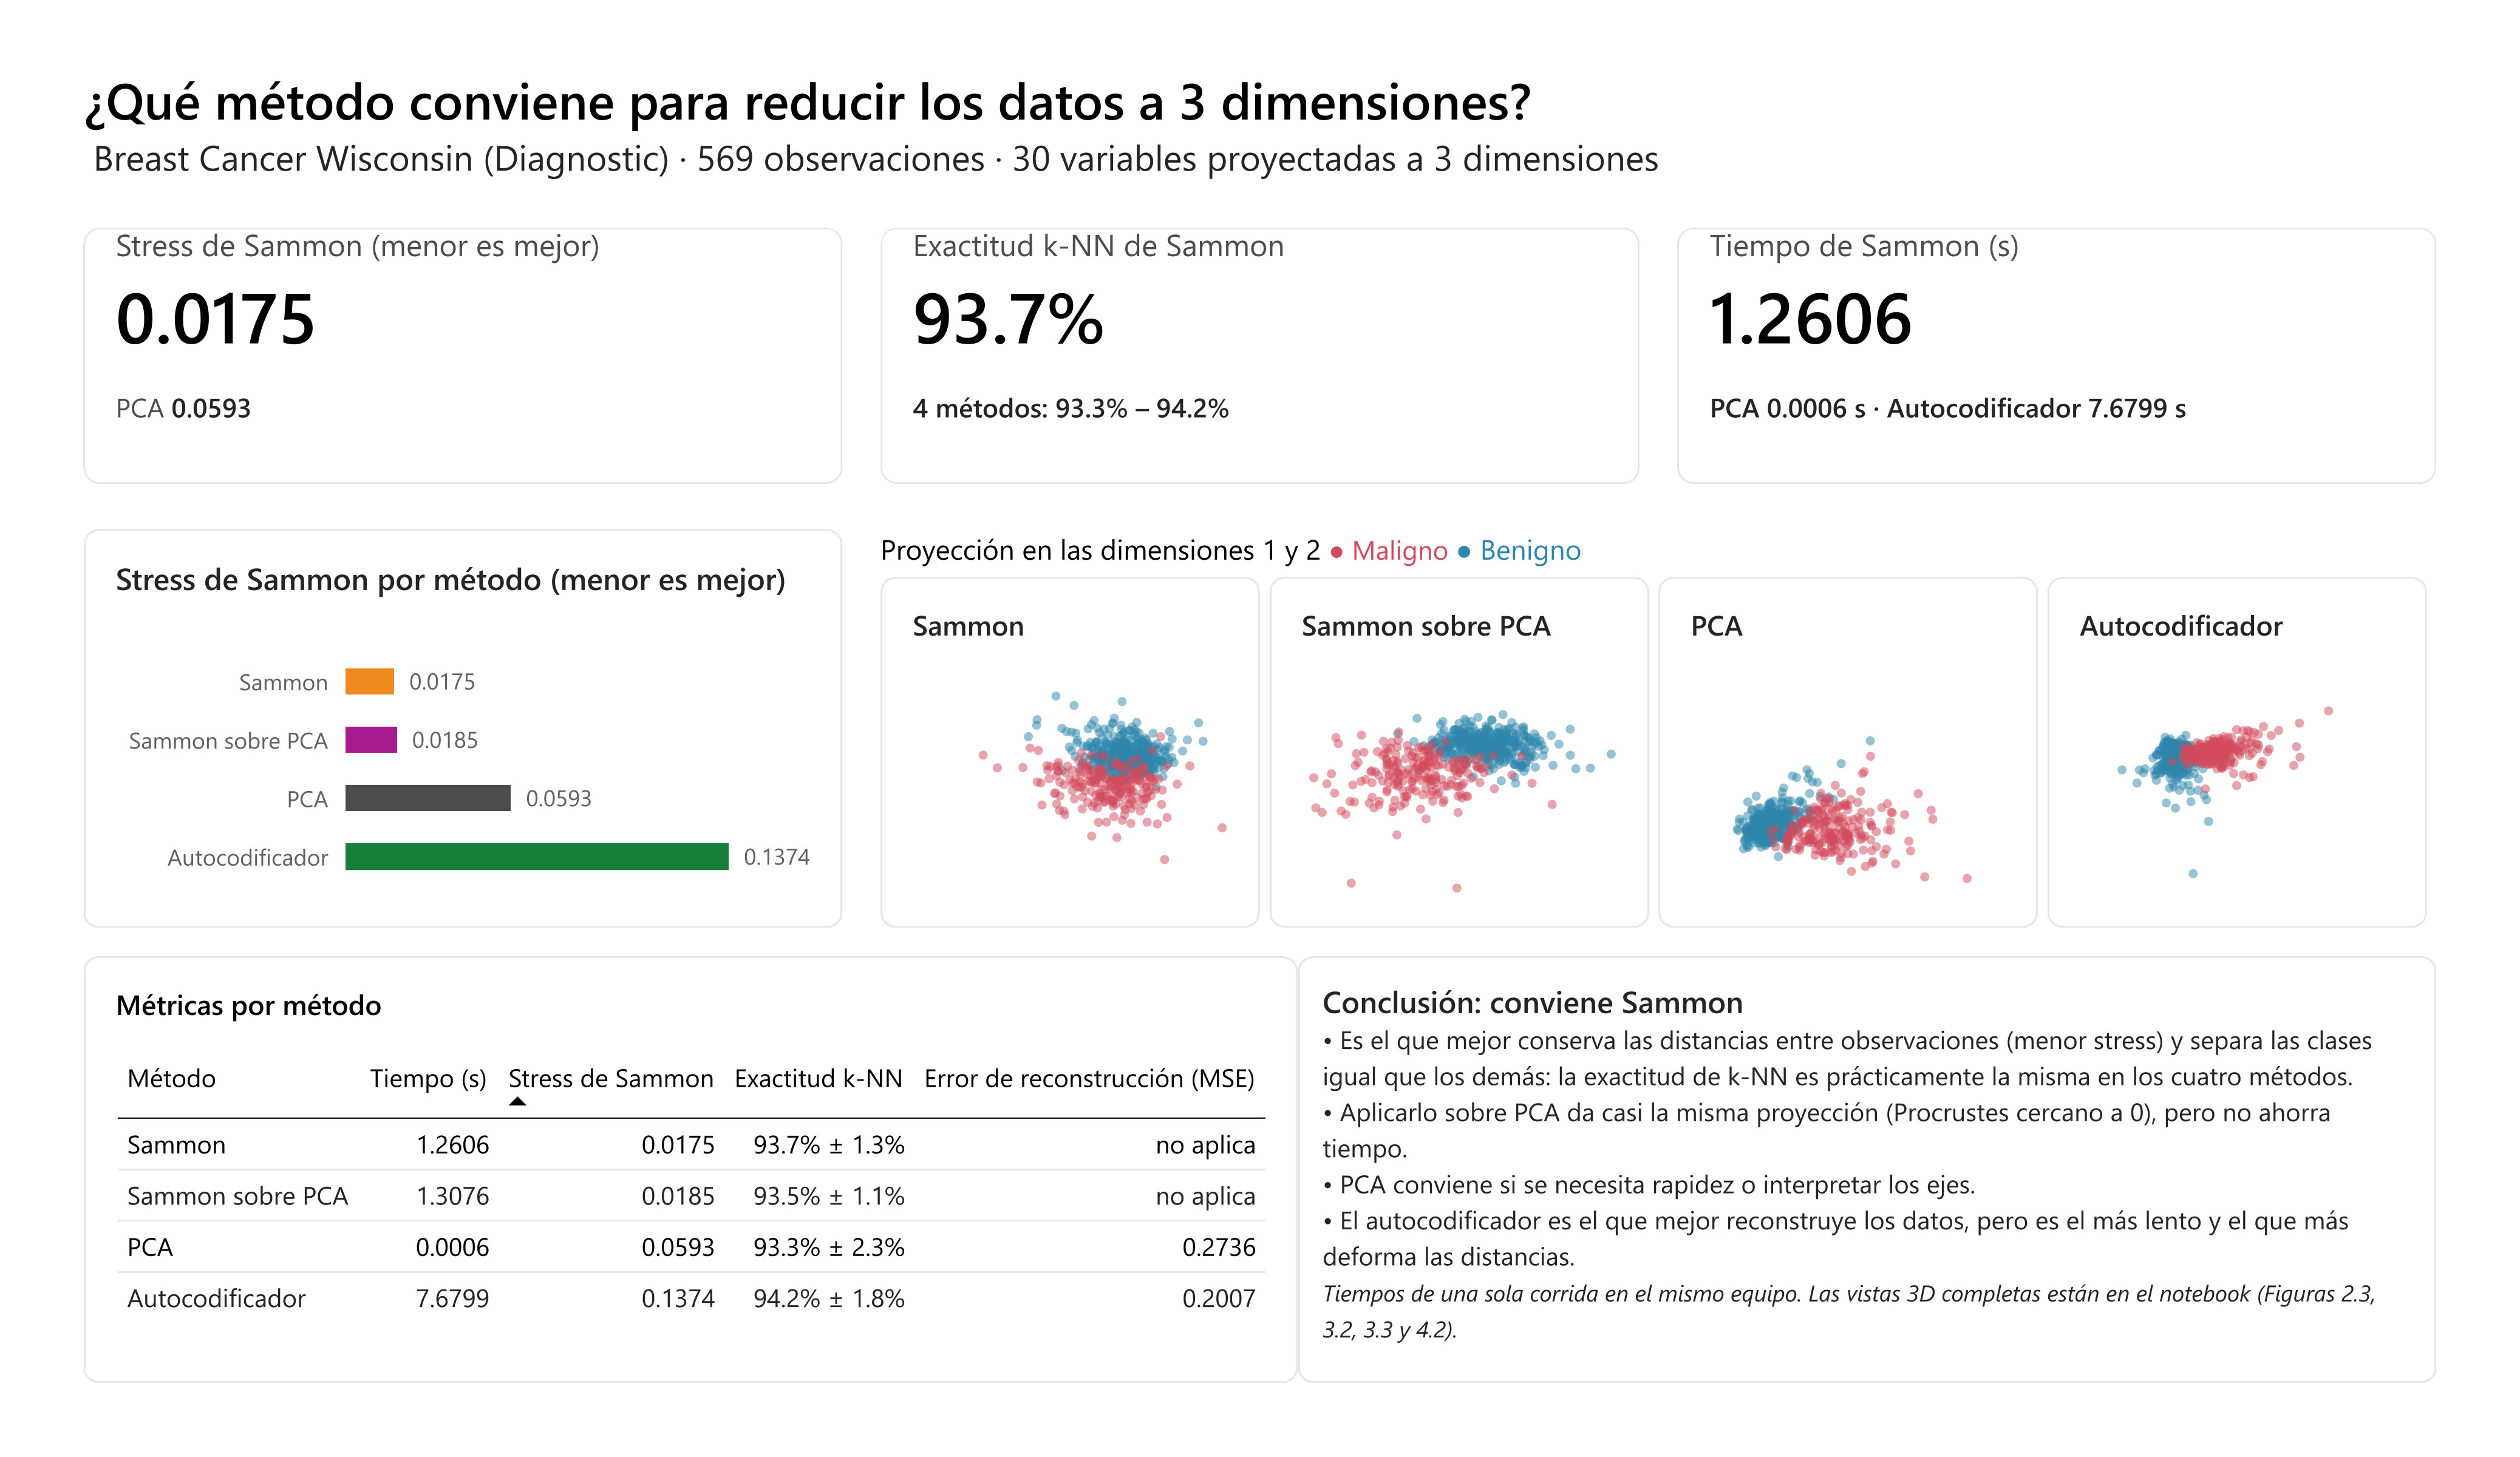

**6c. Justificación del diseño.** El tablero se diseñó para responder qué método conviene. Primero, la distribución sigue una pirámide invertida: arriba la pregunta y tres indicadores de Sammon, cada uno con una referencia para no presentar datos aislados; en medio la evidencia, y abajo la tabla completa y la conclusión, de modo que se lee de arriba abajo y de izquierda a derecha. Segundo, se eligieron barras horizontales ordenadas de menor a mayor stress, porque comparan categorías y dejan al mejor método arriba, y dispersiones 2D lado a lado en lugar de 3D, porque en una pantalla plana el 3D oculta puntos y dificulta comparar los cuatro métodos. Tercero, la paleta tiene significado constante: rojo y azul para las clases y un color fijo por método, igual que en el notebook; lo demás va en grises y sin elementos decorativos, para que la atención vaya a los datos.